<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/sugarcane-yield-quality-prediction/blob/main/03_comparacion_modelos_suertes.ipynb)

# **Proyecto Caña de Azúcar**
## Modelado y generación de insights para el TCH y la sacarosa en el Ingenio Providencia


--------------------------------------------------------------------

**Aprendizaje Automático II - Proyecto final**

**Profesor:** Anibal Sosa

**Integrantes:**

*   Juan David Martínez Legarda
*   Daniel Velasco López
*   Juan Esteban Cardona García
*   Katherin Adriana Camargo Cetina

Fecha: 22/11/2026

________________________________________________________________________

# Histórico de suertes: comparación de modelos de regresión

En este notebook se construyen y comparan modelos para anticipar el tonelaje (`TCH`, toneladas de caña por hectárea) y la calidad (`%Sac.Caña`, porcentaje de sacarosa) de cada suerte del Ingenio Providencia en el momento de programar su corte. Varios predictores, como la edad del cultivo a la cosecha y la lluvia de los últimos meses del ciclo, solo se conocen completos cerca de la fecha de corte. Por eso los modelos describen ese escenario y no un pronóstico con meses de anticipación.

El recorrido va de lo simple a lo complejo: una media constante como piso, la regresión lineal múltiple como modelo de referencia interpretable, Ridge y Lasso como chequeo de regularización, y Random Forest y XGBoost como modelos avanzados. Por último, se prueba si el resultado del corte anterior de cada lote mejora la predicción de todos ellos.

Para que la comparación sea justa, todos los modelos comparten el preprocesamiento, la partición en entrenamiento y prueba, los pliegues de validación cruzada y el criterio de selección. Así, una diferencia de desempeño se puede atribuir al modelo y no a la forma de evaluarlo.

**Criterios generales**

- La partición 80/20 se hace al inicio y se agrupa por hacienda: ninguna finca aparece a la vez en entrenamiento y en prueba.
- Los hiperparámetros y la selección de modelos se deciden con validación cruzada de 5 pliegues sobre el entrenamiento, con la misma agrupación. Todos los modelos se evalúan en los mismos pliegues y con un número comparable de configuraciones.
- La imputación, la agrupación de categorías raras y la codificación se estiman dentro de un `Pipeline`, de modo que en cada pliegue solo usan los datos de entrenamiento de ese pliegue.
- El conjunto de prueba se usa una sola vez, al final, con todos los modelos ya elegidos.
- Las métricas son R², RMSE y MAE. El RMSE es el criterio de selección, porque penaliza más los errores grandes; el MAE se lee en las unidades del target (t/ha o puntos de sacarosa).

**Estructura**

1. Carga del histórico limpio
2. Preprocesamiento
3. Partición en entrenamiento y prueba
4. Modelos de referencia: media constante, regresión lineal múltiple, Ridge y Lasso
5. Modelos avanzados: Random Forest, XGBoost e historial del lote
6. Comparación en validación cruzada y elección del modelo
7. Evaluación en el conjunto de prueba
8. Interpretabilidad
9. Conclusiones

## Punto de partida: qué dejó el análisis exploratorio

El EDA y la preparación de los datos se hicieron en `01_eda_suertes.ipynb`. A continuación se resume lo que se necesita de ese trabajo para el modelado.

**Los datos.** `HISTORICO_SUERTES.xlsx` tiene 21 027 cosechas y 85 columnas, entre enero de 2017 y julio de 2024. Cada fila es una suerte (un lote, identificado por `Hacienda` y `Suerte`) cosechada en un mes (`Período`, en formato AAAAMM). Un mismo lote aparece varias veces en el histórico, una por cada corte. La población es amplia: incluye lotes madurados y sin madurante, cosecha mecánica y manual, manejo convencional y orgánico, y 58 variedades.

**Los dos targets**

| | `TCH` | `%Sac.Caña` |
|---|---|---|
| Qué mide | Productividad: toneladas de caña por hectárea | Calidad: porcentaje de sacarosa en la caña |
| Distribución | Casi simétrica, con media cercana a 130 t/ha | Concentrada, con media de 12.3 % y rango de 7.1 a 18.4 % |
| Registros que se excluyen | 355 lotes de destino molino con TCH menor que 60 t/ha, que por criterio de negocio se consideran atípicos. Los valores altos (hasta 401 t/ha) corresponden a lotes de área pequeña y se conservan | Los 449 registros sin valor medido, en su mayoría lotes de semilla que no pasan por el laboratorio. El target no se imputa |

La correlación entre los dos targets es de −0.17: más caña no implica más azúcar. Por eso se modelan como dos problemas independientes, con el mismo conjunto de predictores.

**Lo que quedó fuera de los predictores**

| Columnas | Motivo |
|---|---|
| Fertilizantes y variables de la estación meteorológica (temperatura, humedad, radiación, evaporación) | 70 % o más de nulos. La estación no tiene registros en la mayor parte del histórico, y la fertilización casi no se registró |
| `Nombre`, `Hacienda`, `Suerte` y los códigos de texto duplicados (`Cod.Estado`, `Cod. T.Cultivo`) | Identifican el registro, no describen el cultivo |
| Toneladas, azúcar por hectárea, `TCHM`, `Rdto`, mediciones de laboratorio (`%ATR`, Brix, Pureza, etc.) y `Vejez` | Se miden después del corte o se derivan del propio target. Usarlas sería fuga de información |
| `Lluvias Ciclo` | Es la suma exacta de las cuatro ventanas de lluvia del ciclo |
| Edad desde la siembra | Repite el número de corte |
| `Area Neta` | El TCH ya está expresado por hectárea |
| `Producto` | Su información ya está en la dosis y las semanas de madurante |
| `Cerca de` (municipio más cercano) | Repite en gran parte la zona |
| `Cosechó`, `D.S.`, `DDUlt.Riego` y las fechas (`F.Siembra`, `F.Ult.Corte`, `Ult.Riego`, `Fec.Madur.`) | Casi constantes, con muchos nulos o ya resumidas en la edad del ciclo y las semanas de madurante |
| `Sac.Caña Precosecha` y `Edad.Precosecha` | Muestreo tomado antes del corte. Su uso como predictor se revisa en la sección 1.1 |

**Los predictores y su justificación**

| Grupo | Variables | Por qué entran | Tratamiento de los vacíos y niveles raros |
|---|---|---|---|
| Ciclo del cultivo | `Edad Ult Cos` (meses del ciclo actual), `Cod.Estado #` (número de corte) | La edad a la cosecha y el envejecimiento de la soca determinan el tonelaje | Sin nulos |
| Maduración | `Dosis Madurante` (L/ha), `Semanas mad.` (desde la aplicación hasta el corte) | El madurante es la principal palanca de manejo sobre la sacarosa | Dosis sin dato = no se aplicó madurante; semanas = 0 en lotes sin madurante |
| Lluvia | Ventanas de 0–3, 3–6, 6–9 y 9 meses a cosecha, lluvia de los 2 meses previos, `lluvia_sin_dato` | El efecto de la lluvia depende de la fase del ciclo | Los ceros son, en su mayoría, falta de medición: se conservan y se marcan con la bandera |
| Riego | `Num.Riegos`, `M3 Riego` | Complementa el agua de lluvia | Sin dato de riegos y sin volumen de agua = no se regó |
| Ubicación | `Zona`, `Suelo`, `Dist Km` | La zona agroecológica y el suelo definen el potencial productivo | `Suelo` sin dato es una categoría propia (fincas sin estudio de suelos). Distancia imputada por zona |
| Manejo | `Variedad`, `T.Corte`, `Tipo Quema`, `Cultivo` (normal u orgánico), `Tenencia`, `Destino 1=Semilla` | Cada variedad tiene su propio potencial y curva de maduración; el manejo orgánico no usa madurante químico | Variedades, suelos y tenencias poco frecuentes se agrupan en `OTRAS` |
| Tiempo | `Año`, `Mes` | Tendencia entre años y estacionalidad de la cosecha | Se derivan de `Período` |

**Relaciones que encontró el EDA**

- El TCH baja de unas 148 t/ha en plantilla a unas 115 t/ha hacia el corte 9 o 10, y desde ahí se aplana. Es un codo, no una recta.
- La edad del ciclo se asocia positivamente con el TCH (correlación de 0.30) y la dosis de madurante con la sacarosa (0.29).
- La lluvia de los primeros 3 meses se asocia con menos tonelaje, y la de los 2 meses previos al corte con menos sacarosa: una correlación de Spearman de −0.23, coherente con la dilución del azúcar al final del ciclo.
- El efecto de la lluvia temprana sobre el TCH cambia de signo según la variedad: hay interacción entre clima y variedad.
- `Dist Km` tiene una correlación lineal casi nula con el TCH, pero una relación en forma de curva por tramos de distancia. Además, toma un único valor por hacienda, así que en parte funciona como identificador de la finca.
- El cultivo orgánico tiene un tonelaje parecido al convencional, pero menos sacarosa (10.6 % frente a 12.4 %).

**Limitaciones de los datos**

- Los datos de la estación meteorológica no cubren la mayor parte del histórico, y la fertilización casi no se registró. El clima se representa solo con la lluvia del lote.
- Más de un tercio de los registros no tiene lluvia medida.
- Algunas decisiones del EDA (selección de predictores, umbrales de agrupación, criterio de atípicos) se tomaron mirando todo el histórico. No estiman ningún estadístico que usen los modelos, pero conviene tenerlas presentes al leer el desempeño en prueba.

In [1]:
# Librerías generales del notebook. Los módulos de scikit-learn se importan en la sección donde se usan.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels
import statsmodels.api as sm
import xgboost

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", None)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

%matplotlib inline

# Versiones usadas, para la reproducibilidad de los resultados
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"statsmodels {statsmodels.__version__} | xgboost {xgboost.__version__}")
      

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | statsmodels 0.15.0 | xgboost 3.4.1


## 1. Carga del histórico limpio

La última celda de `01_eda_suertes.ipynb` guarda el histórico en `datos/suertes_limpio.parquet`. El archivo trae solo transformaciones que dan el mismo resultado en cada fila sin importar las demás: tipos de dato, textos de vacío convertidos a nulos, etiquetas unificadas y dos marcas de fila creadas en el EDA:

- **`excluir_tch`** vale `True` en los lotes de destino molino con TCH menor que 60 t/ha. Por criterio de negocio, un tonelaje tan bajo en un lote comercial es atípico. Esos 355 registros no se borran del archivo: solo se excluyen del modelo de `TCH`, y siguen en el de `%Sac.Caña` porque su sacarosa sí está medida.
- **`lluvia_sin_dato`** vale `True` cuando la lluvia de todo el ciclo es cero. La precipitación media del valle geográfico del río Cauca está entre 850 y 2500 mm al año, y la cuenca tiene dos temporadas lluviosas, de marzo a mayo y de septiembre a noviembre [1]. Un ciclo completo sin lluvia no es una sequía sino un registro faltante, y así se trataron esos ceros en el EDA. La marca entra como predictor, para que el modelo distinga la lluvia medida de la no registrada.

El archivo no trae ninguna imputación, porque los estadísticos para imputar deben calcularse solo con el conjunto de entrenamiento.

Antes de modelar se verifica que el archivo conserve lo establecido en el EDA:

- 21 027 cosechas, sin repetir la combinación de lote y periodo.
- Los nulos originales de los predictores que se imputan más adelante. Si alguno cambia, el archivo llegó imputado.
- Las 355 filas con `excluir_tch` y las 7739 con `lluvia_sin_dato`.
- 20 672 registros válidos para `TCH` y 20 578 para `%Sac.Caña`.
- Las columnas `Hacienda`, `Suerte` y `Período`, que no son predictores pero se necesitan para agrupar la partición.

Si alguna verificación falla, el notebook se detiene.

**Referencias**

[1] J. D. Mera Franco y C. Y. Soto Chávez, "Análisis espaciotemporal de las tendencias de precipitación y temperatura en la cuenca del río Cauca y el Pacífico vallecaucano," Corporación Autónoma Regional del Valle del Cauca (CVC), Santiago de Cali, Colombia, Informe técnico, dic. 2024. [En línea]. Disponible: https://ecopedia.cvc.gov.co/sites/default/files/archivosAdjuntos/Informe%20Tendencias%20Precipitacion%20Temperatura.pdf

In [2]:
# 1. Carga del histórico limpio (salida de 01_eda_suertes.ipynb) y verificación de sus propiedades
RANDOM_STATE = 42  # semilla común a la partición, los pliegues y los modelos (la misma de AA1)
RUTA_SUERTES = Path("datos/suertes_limpio.parquet")

# Propiedades del archivo establecidas en 01_eda_suertes.ipynb
FILAS_ESPERADAS = 21_027
NULOS_ORIGINALES = {"Semanas mad.": 9_775, "Num.Riegos": 12_589, "Dosis Madurante": 104, "Suelo": 3_758}
FILAS_EXCLUIR_TCH = 355
FILAS_LLUVIA_SIN_DATO = 7_739
FILAS_VALIDAS_POR_TARGET = {"TCH": 20_672, "%Sac.Caña": 20_578}
COLUMNAS_REQUERIDAS = [
    "Hacienda", "Suerte", "Período", "TCH", "%Sac.Caña", "excluir_tch", "lluvia_sin_dato",
    "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve", "Luvias 9 -FC", "Lluvias (2 Meses Ant.)",
]


def formato_miles(numero):
    """Entero con espacio como separador de miles a partir de cinco cifras (21 027), según la RAE."""
    return f"{numero:,}".replace(",", " ") if abs(numero) >= 10_000 else str(numero)


def filas_validas(df, target):
    """Máscara de los registros con los que se modela cada target, sin imputarlo.

    TCH excluye los lotes marcados con excluir_tch (TCH < 60 t/ha de destino molino) y
    %Sac.Caña conserva solo los registros con valor medido.
    """
    if target == "TCH":
        return ~df["excluir_tch"]
    return df["%Sac.Caña"].notna()


def verificar_historico(df):
    """Detiene el notebook si el archivo no conserva las propiedades establecidas en el EDA."""
    faltantes = [col for col in COLUMNAS_REQUERIDAS if col not in df.columns]
    assert not faltantes, f"Faltan columnas: {faltantes}"
    assert len(df) == FILAS_ESPERADAS, (
        f"Se esperaban {formato_miles(FILAS_ESPERADAS)} filas y llegaron {formato_miles(len(df))}"
    )
    assert not df.duplicated(["Hacienda", "Suerte", "Período"]).any(), "La combinación lote + periodo se repite"

    # Si algún nulo cambió, el archivo llegó imputado
    for col, nulos_esperados in NULOS_ORIGINALES.items():
        nulos = df[col].isna().sum()
        assert nulos == nulos_esperados, (
            f"{col}: {formato_miles(nulos)} nulos, se esperaban {formato_miles(nulos_esperados)}"
        )

    assert df["excluir_tch"].sum() == FILAS_EXCLUIR_TCH, "Cambió el número de filas con excluir_tch"
    assert df["lluvia_sin_dato"].sum() == FILAS_LLUVIA_SIN_DATO, "Cambió el número de filas con lluvia_sin_dato"
    for target, filas_esperadas in FILAS_VALIDAS_POR_TARGET.items():
        assert filas_validas(df, target).sum() == filas_esperadas, f"Cambió el número de registros válidos de {target}"


if not RUTA_SUERTES.exists():
    raise FileNotFoundError(
        f"No existe {RUTA_SUERTES}. Ejecutar antes 01_eda_suertes.ipynb: su última celda genera el archivo."
    )

df_suertes = pd.read_parquet(RUTA_SUERTES)
verificar_historico(df_suertes)

n_lotes = df_suertes.groupby(["Hacienda", "Suerte"]).ngroups
print(f"Histórico limpio: {formato_miles(df_suertes.shape[0])} filas × {df_suertes.shape[1]} columnas")
print(f"Haciendas: {formato_miles(df_suertes['Hacienda'].nunique())} | lotes: {formato_miles(n_lotes)} | "
      f"cortes por lote: {len(df_suertes) / n_lotes:.1f} en promedio")
print(f"Periodos: {df_suertes['Período'].nunique()} (de {df_suertes['Período'].min()} a {df_suertes['Período'].max()})")
for target in FILAS_VALIDAS_POR_TARGET:
    print(f"Registros válidos de {target}: {formato_miles(filas_validas(df_suertes, target).sum())}")

Histórico limpio: 21 027 filas × 88 columnas
Haciendas: 926 | lotes: 5799 | cortes por lote: 3.6 en promedio
Periodos: 91 (de 201701 a 202407)
Registros válidos de TCH: 20 672
Registros válidos de %Sac.Caña: 20 578


### 1.1 Sacarosa precosecha

En el EDA, `Sac.Caña Precosecha` se identificó como una medición tomada antes del corte y no como fuga de información, pero quedó fuera del conjunto final de predictores sin un análisis específico. Es la única variable del histórico que mide directamente el contenido de sacarosa del lote antes de cosecharlo, así que se revisa si puede entrar al modelo. Para eso debe cumplir tres condiciones:

- **Cobertura.** Que los registros con muestreo no se concentren en un solo periodo, como ocurre con la estación meteorológica.
- **Momento de la medición.** Que la muestra se tome antes del corte. Se compara la edad del cultivo al muestrear (`Edad.Precosecha`) con la edad a la cosecha (`Edad Ult Cos`).
- **Relación con el target.** Que tenga una asociación con `%Sac.Caña` que justifique incluirla, sin ser casi idéntica a ella. Una correlación cercana a 1 indicaría que la medición no se distingue del resultado del corte.

In [3]:
# 1.1 Sacarosa precosecha: cobertura, momento de la medición y relación con el target
COLUMNA_PRECOSECHA = "Sac.Caña Precosecha"
RANGO_PLAUSIBLE_SACAROSA = (df_suertes["%Sac.Caña"].min(), df_suertes["%Sac.Caña"].max())  # rango del target

precosecha = df_suertes[COLUMNA_PRECOSECHA]
# Una sacarosa de 0 % no es posible: los ceros son faltantes disfrazados, como en la lluvia
muestra_valida = precosecha.notna() & (precosecha > 0)

print(f"Nulos: {precosecha.isna().mean():.1%} | ceros: {(precosecha == 0).mean():.1%} | "
      f"valores mayores que 0: {muestra_valida.mean():.1%} ({formato_miles(muestra_valida.sum())} registros)")

# Distribución de los valores válidos frente al rango del target
valores_validos = precosecha[muestra_valida]
fuera_de_rango = ~valores_validos.between(*RANGO_PLAUSIBLE_SACAROSA)
print(f"\nValores mayores que 0: mediana {valores_validos.median():.2f} | "
      f"p5 {valores_validos.quantile(0.05):.2f} | p95 {valores_validos.quantile(0.95):.2f} | "
      f"máximo {valores_validos.max():.2f}")
print(f"Fuera del rango de %Sac.Caña ({RANGO_PLAUSIBLE_SACAROSA[0]:.1f} a {RANGO_PLAUSIBLE_SACAROSA[1]:.1f}): "
      f"{fuera_de_rango.mean():.1%}")

# Cobertura de los valores válidos por año de cosecha
cobertura_por_año = (df_suertes.assign(año=df_suertes["Período"] // 100, muestra_valida=muestra_valida)
                     .groupby("año")["muestra_valida"].agg(registros="size", proporcion_valida="mean"))
print("\nProporción de registros con muestra válida por año:")
display(cobertura_por_año.round(3))

# Momento de la medición, solo en registros con muestra válida y edad de muestreo registrada
con_edad_muestreo = muestra_valida & df_suertes["Edad.Precosecha"].notna()
meses_antes_del_corte = (df_suertes.loc[con_edad_muestreo, "Edad Ult Cos"]
                         - df_suertes.loc[con_edad_muestreo, "Edad.Precosecha"])
print(f"Meses entre la muestra y el corte (n = {formato_miles(con_edad_muestreo.sum())}): "
      f"mediana {meses_antes_del_corte.median():.2f} | "
      f"muestras posteriores al corte: {(meses_antes_del_corte < 0).mean():.1%}")

# Relación con el target, solo en registros con muestra válida y sacarosa medida
pares_validos = df_suertes.loc[muestra_valida & df_suertes["%Sac.Caña"].notna(), [COLUMNA_PRECOSECHA, "%Sac.Caña"]]
print(f"\nCorrelación con %Sac.Caña en registros con muestra válida (n = {formato_miles(len(pares_validos))}): "
      f"Pearson {pares_validos.corr().iloc[0, 1]:.3f} | "
      f"Spearman {pares_validos.corr(method='spearman').iloc[0, 1]:.3f}")

Nulos: 5.2% | ceros: 51.2% | valores mayores que 0: 43.6% (9159 registros)

Valores mayores que 0: mediana 17.07 | p5 15.05 | p95 18.52 | máximo 44.78
Fuera del rango de %Sac.Caña (7.1 a 18.4): 6.5%

Proporción de registros con muestra válida por año:


,registros,proporcion_valida
año,,
2017,2517,0.785
2018,2879,0.785
2019,2852,0.788
2020,2889,0.796
2021,2504,0.143
2022,2932,0.004
2023,3022,0.003
2024,1432,0.001


Meses entre la muestra y el corte (n = 8754): mediana 0.59 | muestras posteriores al corte: 6.9%

Correlación con %Sac.Caña en registros con muestra válida (n = 9144): Pearson 0.304 | Spearman 0.371


### Conclusión de la sección 1

El archivo cumple todas las verificaciones. Tiene 21 027 filas y 88 columnas: las 85 del Excel original más tres creadas en el EDA (la edad desde la siembra, `excluir_tch` y `lluvia_sin_dato`). Los nulos de los predictores son los originales, así que toda la imputación queda por hacer dentro del modelado.

Las cosechas provienen de 926 haciendas y 5799 lotes, en 91 periodos entre enero de 2017 y julio de 2024. Cada lote aparece en promedio 3.6 veces, una por corte, y cada hacienda agrupa varios lotes. Esa estructura es la que obliga a agrupar la partición, para que el conjunto de prueba no comparta fincas con el entrenamiento.

Se modelan 20 672 cosechas para `TCH` y 20 578 para `%Sac.Caña`.

**`Sac.Caña Precosecha` queda fuera de los predictores.** Solo el 5.2 % de los registros está vacío, pero el 51.2 % tiene un cero, que no es una medición posible. Los valores válidos cubren el 43.6 % del histórico y se concentran entre 2017 y 2020 (entre el 78 % y el 80 % de los registros de cada año); bajan al 14 % en 2021 y desaparecen desde 2022. Un modelo que dependiera de esta variable no podría aplicarse a las cosechas actuales, y la ausencia de la muestra se confundiría con el año de cosecha. Además, sus valores no están en la misma escala que el target: la mediana es 17.1, cerca del extremo superior del rango de `%Sac.Caña` (7.1 a 18.4), y el 6.5 % cae fuera de ese rango. El 6.9 % de las muestras con edad registrada sería posterior al corte. Su relación con la sacarosa de la cosecha es moderada (Spearman de 0.37). El muestreo precosecha podría ser un predictor útil si el Ingenio lo registrara de forma continua y en la misma base que la sacarosa de la cosecha.

## 2. Preprocesamiento

El preprocesamiento aplica las reglas de imputación y codificación definidas en el EDA. Se implementa como un transformador de scikit-learn y no como pasos sueltos sobre el DataFrame, por dos razones:

- Dentro de un `Pipeline`, la validación cruzada y la búsqueda de hiperparámetros reajustan el transformador en cada pliegue, de modo que cada estadístico se calcula solo con los datos de entrenamiento de ese pliegue.
- El conjunto de prueba recibe exactamente las mismas transformaciones, con los valores aprendidos en el entrenamiento.

### 2.1 Reglas de negocio y transformador

Las reglas son de dos tipos:

- **Sin estado.** El resultado de cada fila no depende de las demás, así que se aplican igual en entrenamiento y en prueba: dosis de madurante sin dato → 0 (no se aplicó), semanas de madurante → 0 en lotes sin madurante, riegos sin dato → 0 cuando el volumen de agua es 0, `Período` separado en `Año` y `Mes`, y fusión de los niveles con un único registro.
- **Estimadas en el ajuste.** La mediana de `Semanas mad.` en los lotes madurados, la mediana de `Num.Riegos` en los lotes con riego, la distancia, la tenencia y el sistema de cultivo por zona (con el valor global como respaldo), los niveles de variedad, suelo y tenencia con suficientes registros para tener columna propia, y la categoría de referencia de cada variable categórica.

Cuatro decisiones adicionales:

- **`madurada`** (si el lote recibió madurante) se usa para imputar `Semanas mad.`, pero no entra como predictor. Casi repite la información de la dosis, porque una dosis de 0 equivale a no haber madurado (correlación de 0.92 en el EDA).
- **`Año` se centra en 2017**, para que el intercepto del modelo lineal corresponda al primer año del histórico y no a un año 0 que no existe en los datos.
- **La categoría de referencia** de cada variable categórica es su nivel más frecuente en el ajuste, sin contar los niveles residuales (`OTRAS`, `SIN DATO`, `NO DEF.`). Así, el coeficiente de cada indicadora se lee como la diferencia frente a la condición más común en el ingenio, y no frente a un nivel elegido por orden alfabético, como en AA1.
- **El transformador devuelve un `DataFrame` con los nombres de las columnas.** Los nombres se necesitan para leer coeficientes e importancias en las secciones 4 y 8.

In [4]:
# 2.1 Reglas de negocio y transformador de preprocesamiento del histórico de suertes
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

AÑO_REFERENCIA = 2017  # el intercepto del modelo lineal corresponde al primer año del histórico

# Predictores que entran a los modelos. madurada no entra: casi repite a Dosis Madurante.
PREDICTORES_NUMERICOS = [
    "Edad Ult Cos", "Cod.Estado #", "Dist Km", "Dosis Madurante", "Semanas mad.",
    "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve", "Luvias 9 -FC",
    "Lluvias (2 Meses Ant.)", "lluvia_sin_dato", "Num.Riegos", "M3 Riego",
    "Destino 1=Semilla", "Año",
]
PREDICTORES_CATEGORICOS = [
    "Zona_agrup", "Variedad_agrup", "Suelo_agrup", "T.Corte_agrup",
    "Tipo Quema", "Cultivo", "Tenencia_agrup", "Mes",
]
# Mínimo de registros para que un nivel tenga columna propia; los demás se agrupan en OTRAS
MINIMO_REGISTROS_POR_NIVEL = {"Variedad": 200, "Suelo": 300, "Tenencia": 200}
# Niveles residuales que no sirven como base de comparación de los coeficientes
NIVELES_RESIDUALES = {"OTRAS", "SIN DATO", "NO DEF."}

# Columnas crudas que necesita el preprocesamiento: predictores originales y columnas auxiliares
COLUMNAS_CRUDAS = [
    "Edad Ult Cos", "Cod.Estado #", "Dist Km", "Dosis Madurante", "Producto", "Semanas mad.",
    "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve", "Luvias 9 -FC",
    "Lluvias (2 Meses Ant.)", "lluvia_sin_dato", "Num.Riegos", "M3 Riego", "Destino 1=Semilla",
    "Período", "Zona", "Variedad", "Suelo", "T.Corte", "Tipo Quema", "Cultivo", "Tenencia",
]


def moda(serie):
    """Valor más frecuente ignorando los nulos (NaN si la serie no tiene valores)."""
    modas = serie.dropna().mode()
    return modas.iloc[0] if len(modas) else np.nan


def aplicar_reglas_negocio(df):
    """Recodificaciones sin estado: el resultado de cada fila no depende de las demás."""
    datos = df.copy()

    # Madurante: sin dosis ni producto registrados significa que no se aplicó
    datos["madurada"] = ((datos["Dosis Madurante"].fillna(0) > 0) | datos["Producto"].notna()).astype(int)
    datos["Dosis Madurante"] = datos["Dosis Madurante"].fillna(0)
    # Semanas negativas son un error de captura; sin madurante, las semanas desde su aplicación son 0
    datos.loc[datos["Semanas mad."] < 0, "Semanas mad."] = np.nan
    sin_madurante = datos["madurada"] == 0
    datos.loc[sin_madurante, "Semanas mad."] = datos.loc[sin_madurante, "Semanas mad."].fillna(0)

    # Riego: sin número de riegos y sin volumen de agua significa que no se regó
    datos.loc[datos["Num.Riegos"].isna() & (datos["M3 Riego"] == 0), "Num.Riegos"] = 0

    # Período (AAAAMM) no es una escala: se separa en tendencia (Año) y estacionalidad (Mes)
    datos["Año"] = datos["Período"] // 100 - AÑO_REFERENCIA
    datos["Mes"] = (datos["Período"] % 100).astype(str).str.zfill(2)

    # Niveles con un único registro o sin significado propio
    datos["Zona_agrup"] = datos["Zona"].replace({"IC07": "OTRAS"})
    datos["T.Corte_agrup"] = datos["T.Corte"].replace({"SEMILLA": "OTRAS"})
    # SEMILLA no es un tipo de quema: repite la información de Destino 1=Semilla
    datos["Tipo Quema"] = datos["Tipo Quema"].replace({"SEMILLA": "VERDE"})
    return datos


def nivel_mas_frecuente(serie):
    """Nivel más frecuente que no sea residual; si todos son residuales, el más frecuente."""
    conteo = serie.value_counts()
    no_residuales = conteo[~conteo.index.isin(NIVELES_RESIDUALES)]
    return (no_residuales if len(no_residuales) else conteo).idxmax()


class PreprocesadorSuertes(BaseEstimator, TransformerMixin):
    """Imputación, agrupación de niveles poco frecuentes y codificación indicadora del histórico.

    Todo lo que se estima a partir de los datos (medianas, modas por zona, niveles que se conservan
    y categorías de referencia) se aprende en fit(). Dentro de un Pipeline, la validación cruzada
    lo recalcula en cada pliegue con los datos de entrenamiento de ese pliegue.

    Parámetros
    ----------
    referencia : {"frecuente", "alfabetica"}
        Cómo se elige la categoría de referencia de cada variable categórica: su nivel más
        frecuente no residual (por defecto) o el primero en orden alfabético (la regla de AA1).
    """

    def __init__(self, referencia="frecuente"):
        self.referencia = referencia

    def fit(self, X, y=None):
        if self.referencia not in {"frecuente", "alfabetica"}:
            raise ValueError(f"referencia debe ser 'frecuente' o 'alfabetica', no {self.referencia!r}")
        datos = aplicar_reglas_negocio(X)

        # Imputación condicionada al significado del vacío
        self.mediana_semanas_madurados_ = datos.loc[datos["madurada"] == 1, "Semanas mad."].median()
        self.mediana_riegos_con_riego_ = datos.loc[datos["M3 Riego"] > 0, "Num.Riegos"].median()
        # Atributos de la finca: se imputan con el valor típico de su zona
        self.distancia_por_zona_ = datos.groupby("Zona")["Dist Km"].median()
        self.tenencia_por_zona_ = datos.groupby("Zona")["Tenencia"].agg(moda)
        self.cultivo_por_zona_ = datos.groupby("Zona")["Cultivo"].agg(moda)
        self.distancia_global_ = datos["Dist Km"].median()
        self.tenencia_global_ = moda(datos["Tenencia"])
        self.cultivo_global_ = moda(datos["Cultivo"])
        datos = self._imputar(datos)

        # Niveles con suficientes registros para tener columna propia
        self.niveles_conservados_ = {}
        for columna, minimo in MINIMO_REGISTROS_POR_NIVEL.items():
            conteo = datos[columna].value_counts()
            self.niveles_conservados_[columna] = set(conteo[conteo >= minimo].index)
        datos = self._agrupar_niveles(datos)

        # Categoría de referencia de cada categórica. Su indicadora se elimina para evitar
        # colinealidad exacta con el intercepto.
        categoricas = datos[PREDICTORES_CATEGORICOS].astype(str)
        if self.referencia == "frecuente":
            self.niveles_referencia_ = {col: nivel_mas_frecuente(categoricas[col]) for col in PREDICTORES_CATEGORICOS}
        else:
            self.niveles_referencia_ = {col: categoricas[col].min() for col in PREDICTORES_CATEGORICOS}
        columnas_referencia = [f"{col}_{nivel}" for col, nivel in self.niveles_referencia_.items()]
        self.columnas_indicadoras_ = pd.get_dummies(categoricas, dtype=float).columns.drop(columnas_referencia)
        self.nombres_columnas_ = np.array(PREDICTORES_NUMERICOS + list(self.columnas_indicadoras_), dtype=object)
        return self

    def _imputar(self, datos):
        datos = datos.copy()
        datos["Semanas mad."] = datos["Semanas mad."].fillna(self.mediana_semanas_madurados_)
        datos["Num.Riegos"] = datos["Num.Riegos"].fillna(self.mediana_riegos_con_riego_)
        datos["Suelo"] = datos["Suelo"].fillna("SIN DATO")  # finca sin estudio de suelos: categoría propia
        datos["Dist Km"] = (datos["Dist Km"].fillna(datos["Zona"].map(self.distancia_por_zona_))
                            .fillna(self.distancia_global_))
        datos["Tenencia"] = (datos["Tenencia"].fillna(datos["Zona"].map(self.tenencia_por_zona_))
                             .fillna(self.tenencia_global_))
        datos["Cultivo"] = (datos["Cultivo"].fillna(datos["Zona"].map(self.cultivo_por_zona_))
                            .fillna(self.cultivo_global_))
        datos["Tenencia"] = datos["Tenencia"].astype("Int64").astype(str)  # código, no escala numérica
        return datos

    def _agrupar_niveles(self, datos):
        datos = datos.copy()
        for columna, conservados in self.niveles_conservados_.items():
            datos[f"{columna}_agrup"] = datos[columna].where(datos[columna].isin(conservados), "OTRAS")
        return datos

    def transform(self, X):
        check_is_fitted(self, "columnas_indicadoras_")
        datos = self._agrupar_niveles(self._imputar(aplicar_reglas_negocio(X)))
        # Reindexando con las columnas del ajuste: la referencia queda fuera y un nivel que no
        # apareció en el ajuste queda con todas sus indicadoras en 0, como la referencia.
        indicadoras = (pd.get_dummies(datos[PREDICTORES_CATEGORICOS].astype(str), dtype=float)
                       .reindex(columns=self.columnas_indicadoras_, fill_value=0.0))
        return pd.concat([datos[PREDICTORES_NUMERICOS].astype(float), indicadoras], axis=1)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "nombres_columnas_")
        return self.nombres_columnas_


def separar_target(df, target):
    """Registros válidos de un target: columnas crudas que usa el preprocesamiento y valores del target."""
    validos = df.loc[filas_validas(df, target)]
    return validos[COLUMNAS_CRUDAS], validos[target].astype(float)

### 2.2 Verificación del transformador

El transformador reescribe el preprocesamiento usado en AA1 (`02_modelos_regresion.ipynb`). Para confirmar que aplica las mismas reglas, se reproduce un resultado de ese notebook con la referencia alfabética que se usó entonces: el R² de validación cruzada de la regresión lineal con el preprocesamiento reajustado en cada pliegue, que fue de 0.2933 en `TCH` y 0.3408 en `%Sac.Caña`. Para obtenerlo se usan la partición aleatoria y los pliegues de AA1, solo en esta celda; la partición de este notebook se define en la sección 3.

Además se verifica que el transformador, con la referencia que se usa en el resto del notebook, no deje faltantes al transformar registros que no intervinieron en su ajuste, y se listan las categorías de referencia resultantes.

In [5]:
# 2.2 Verificación: reproducir el R² de validación cruzada del modelo lineal de AA1
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline

# Partición aleatoria y pliegues de AA1: se usan solo en esta verificación
indices_train_aa1, indices_test_aa1 = train_test_split(
    df_suertes.index, test_size=0.20, random_state=RANDOM_STATE, shuffle=True
)
df_train_aa1 = df_suertes.loc[indices_train_aa1]
pliegues_aa1 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
R2_CV_AA1 = {"TCH": 0.2933, "%Sac.Caña": 0.3408}  # 02_modelos_regresion.ipynb, paso 23.4
TOLERANCIA_R2 = 5e-4  # los valores de AA1 están redondeados a 4 decimales

for target, r2_aa1 in R2_CV_AA1.items():
    X_verificacion, y_verificacion = separar_target(df_train_aa1, target)
    pipeline_lineal_aa1 = Pipeline([
        ("preprocesamiento", PreprocesadorSuertes(referencia="alfabetica")),  # la regla de AA1
        ("modelo", LinearRegression()),
    ])
    resultados = cross_validate(pipeline_lineal_aa1, X_verificacion, y_verificacion, cv=pliegues_aa1, scoring="r2")
    r2_cv = resultados["test_score"].mean()
    print(f"{target}: R² CV = {r2_cv:.4f} (AA1: {r2_aa1:.4f}) | n = {formato_miles(len(y_verificacion))}")
    assert abs(r2_cv - r2_aa1) < TOLERANCIA_R2, f"{target}: el preprocesamiento no reproduce el de AA1"

# Ajuste con el entrenamiento de AA1 y transformación de registros que no intervinieron en el ajuste
X_ajuste, _ = separar_target(df_train_aa1, "TCH")
preprocesador_verificacion = PreprocesadorSuertes().fit(X_ajuste)
matriz_no_vista = preprocesador_verificacion.transform(df_suertes.loc[indices_test_aa1, COLUMNAS_CRUDAS])

assert matriz_no_vista.isna().sum().sum() == 0, "La transformación dejó faltantes"
assert list(matriz_no_vista.columns) == list(preprocesador_verificacion.get_feature_names_out())

n_indicadoras = len(preprocesador_verificacion.columnas_indicadoras_)
print(f"\nMatriz de diseño: {matriz_no_vista.shape[1]} columnas "
      f"({len(PREDICTORES_NUMERICOS)} numéricas y {n_indicadoras} indicadoras), sin faltantes")
print("Categorías de referencia:")
for columna, referencia in preprocesador_verificacion.niveles_referencia_.items():
    print(f"  {columna}: {referencia}")

TCH: R² CV = 0.2933 (AA1: 0.2933) | n = 16 538
%Sac.Caña: R² CV = 0.3408 (AA1: 0.3408) | n = 16 479

Matriz de diseño: 57 columnas (15 numéricas y 42 indicadoras), sin faltantes
Categorías de referencia:
  Zona_agrup: IP05
  Variedad_agrup: CC01-1940
  Suelo_agrup: CORINTIAS
  T.Corte_agrup: MECANIZADO
  Tipo Quema: VERDE
  Cultivo: Normal
  Tenencia_agrup: 51
  Mes: 01


### Conclusión de la sección 2

Con la referencia alfabética de AA1, el transformador reproduce exactamente el R² de validación cruzada de ese notebook: 0.2933 en `TCH` y 0.3408 en `%Sac.Caña`. Las reglas de imputación y codificación son las mismas, así que los modelos de este notebook parten del preprocesamiento definido en el EDA, ahora estimado dentro de cada pliegue.

Ajustado con el entrenamiento de AA1, el transformador produce 57 columnas: 15 numéricas y 42 indicadoras. El número de indicadoras no es fijo, porque los niveles con suficientes registros para tener columna propia se deciden con los datos del ajuste; con otro conjunto de entrenamiento puede cambiar en unas pocas columnas. En todos los casos, el transformador no deja faltantes al transformar registros que no intervinieron en el ajuste.

Las categorías de referencia corresponden a la condición más común en el histórico: zona IP05, variedad CC01-1940, suelo Corintias, cosecha mecanizada, cosecha en verde, manejo convencional, tenencia 51 y enero como mes de cosecha. En la sección 4, cada coeficiente de una indicadora se lee como la diferencia frente a esa condición.

## 3. Partición en entrenamiento y prueba

La partición tiene que reproducir la forma en que se usaría el modelo. El Ingenio lo aplicaría a cosechas que todavía no ocurren, incluidas las de fincas cuyo historial no está en los datos de ajuste, como las de proveedores nuevos. Si el conjunto de prueba comparte fincas con el entrenamiento, el desempeño medido incluye lo que el modelo aprende de cada finca en particular, y no solo lo que generaliza.

Ese riesgo es concreto en este histórico, por dos razones:

- Un mismo lote aparece en varios cortes, y los lotes de una hacienda comparten suelo, manejo y distancia al ingenio. En AA1, con una partición aleatoria por filas, el 89.7 % de los registros de prueba pertenecía a un lote que también estaba en entrenamiento.
- `Dist Km` toma un único valor por hacienda. Si una finca está en ambos conjuntos, un modelo flexible puede usar la distancia para reconocerla, en lugar de aprender un efecto de la distancia.

Por eso la partición se agrupa por hacienda: todas las cosechas de una finca quedan en el mismo conjunto. Agrupar por lote no bastaría, porque los demás lotes de la misma hacienda seguirían en el otro conjunto. La validación cruzada de la sección 3.3 usa la misma agrupación.

### 3.1 Partición agrupada por hacienda

`GroupKFold` divide las haciendas en cinco grupos de tamaño parecido en número de registros, así que cada grupo es un conjunto de prueba candidato con cerca del 20 % de los datos. La partición es común a los dos targets: se hace sobre las 21 027 cosechas, y después cada target conserva sus registros válidos.

Entre las cinco candidatas se elige una con una regla fija, que no usa ningún modelo: la que tiene la menor diferencia entre la media del target en prueba y en entrenamiento, medida en desviaciones estándar del entrenamiento, considerando el peor de los dos targets. Cumple el mismo papel que la estratificación en una partición aleatoria, que no se puede aplicar directamente cuando se agrupa.

In [6]:
# 3.1 Partición 80/20 agrupada por hacienda, común a los dos targets
from sklearn.model_selection import GroupKFold

TARGETS = list(FILAS_VALIDAS_POR_TARGET)  # TCH y %Sac.Caña
N_CANDIDATAS = 5                          # cinco grupos de haciendas de ~20 % de los registros cada uno
PROPORCION_TEST_ADMISIBLE = (0.18, 0.22)  # tolerancia alrededor del 20 % pedido


def diferencia_estandarizada(valores_train, valores_test):
    """Diferencia de medias (prueba − entrenamiento) en desviaciones estándar del entrenamiento."""
    return (valores_test.mean() - valores_train.mean()) / valores_train.std()


# Cada pliegue de GroupKFold es un conjunto de prueba candidato; las haciendas no se reparten entre pliegues
particionador = GroupKFold(n_splits=N_CANDIDATAS, shuffle=True, random_state=RANDOM_STATE)
particiones_candidatas = list(particionador.split(df_suertes, groups=df_suertes["Hacienda"]))

filas_candidatas = []
for numero, (posiciones_train, posiciones_test) in enumerate(particiones_candidatas):
    candidata_train, candidata_test = df_suertes.iloc[posiciones_train], df_suertes.iloc[posiciones_test]
    fila = {
        "candidata": numero,
        "proporcion_test": len(candidata_test) / len(df_suertes),
        "haciendas_test": candidata_test["Hacienda"].nunique(),
    }
    for target in TARGETS:
        fila[f"diferencia_{target}"] = diferencia_estandarizada(
            candidata_train.loc[filas_validas(candidata_train, target), target],
            candidata_test.loc[filas_validas(candidata_test, target), target],
        )
    filas_candidatas.append(fila)

tabla_candidatas = pd.DataFrame(filas_candidatas).set_index("candidata")
columnas_diferencia = [f"diferencia_{target}" for target in TARGETS]
tabla_candidatas["peor_diferencia"] = tabla_candidatas[columnas_diferencia].abs().max(axis=1)
print("Particiones candidatas (diferencias en desviaciones estándar del entrenamiento):")
display(tabla_candidatas.round(3))

# Regla de elección: proporción de prueba cercana al 20 % y menor diferencia en el peor de los dos targets
admisibles = tabla_candidatas["proporcion_test"].between(*PROPORCION_TEST_ADMISIBLE)
CANDIDATA_ELEGIDA = tabla_candidatas.loc[admisibles, "peor_diferencia"].idxmin()
posiciones_train, posiciones_test = particiones_candidatas[CANDIDATA_ELEGIDA]
df_train = df_suertes.iloc[posiciones_train]
df_test = df_suertes.iloc[posiciones_test]

# Verificaciones: conjuntos disjuntos que cubren todo el histórico, sin haciendas compartidas
assert len(df_train) + len(df_test) == len(df_suertes)
assert df_train.index.intersection(df_test.index).empty
assert set(df_train["Hacienda"]).isdisjoint(df_test["Hacienda"]), "Hay haciendas en ambos conjuntos"

print(f"\nPartición elegida: candidata {CANDIDATA_ELEGIDA}")
for nombre, conjunto in [("Entrenamiento", df_train), ("Prueba", df_test)]:
    n_lotes_conjunto = conjunto.groupby(["Hacienda", "Suerte"]).ngroups
    print(f"  {nombre}: {formato_miles(len(conjunto))} registros ({len(conjunto) / len(df_suertes):.1%}) | "
          f"haciendas: {formato_miles(conjunto['Hacienda'].nunique())} | lotes: {formato_miles(n_lotes_conjunto)} | "
          + " | ".join(f"válidos {t}: {formato_miles(filas_validas(conjunto, t).sum())}" for t in TARGETS))

Particiones candidatas (diferencias en desviaciones estándar del entrenamiento):


,proporcion_test,haciendas_test,diferencia_TCH,diferencia_%Sac.Caña,peor_diferencia
candidata,,,,,
0,0.206,186,-0.031,0.049,0.049
1,0.204,185,0.090,-0.117,0.117
2,0.217,185,0.008,0.052,0.052
3,0.157,185,-0.058,0.118,0.118
4,0.217,185,-0.018,-0.083,0.083



Partición elegida: candidata 0
  Entrenamiento: 16 689 registros (79.4%) | haciendas: 740 | lotes: 4663 | válidos TCH: 16 407 | válidos %Sac.Caña: 16 299
  Prueba: 4338 registros (20.6%) | haciendas: 186 | lotes: 1136 | válidos TCH: 4265 | válidos %Sac.Caña: 4279


### 3.2 Balance entre entrenamiento y prueba

Al agrupar por hacienda, el conjunto de prueba queda formado por fincas completas, y su composición puede diferir de la del entrenamiento más que en una partición aleatoria. Se comparan los dos conjuntos en dos aspectos:

- **Los targets:** media, desviación estándar y mediana.
- **Las condiciones que más los afectan según el EDA:** zona, sistema de cultivo, tipo de corte, destino semilla, lluvia sin medición y año de cosecha. Las diferencias se expresan en puntos porcentuales.

Una diferencia grande en alguna de ellas no invalida la partición, pero hay que tenerla en cuenta al leer el desempeño en prueba.

In [7]:
# 3.2 Balance de los targets y de las condiciones principales entre entrenamiento y prueba
VARIABLES_BALANCE = ["Zona", "Cultivo", "T.Corte", "Destino 1=Semilla", "lluvia_sin_dato", "Año de cosecha"]


def resumen_target(conjunto, target):
    """Media, desviación estándar y mediana de un target en sus registros válidos."""
    valores = conjunto.loc[filas_validas(conjunto, target), target]
    return pd.Series({"media": valores.mean(), "desviación": valores.std(), "mediana": valores.median()})


def comparar_proporciones(columna, train, test):
    """Porcentaje de cada nivel en entrenamiento y prueba, y su diferencia en puntos porcentuales."""
    tabla = 100 * pd.concat({
        "entrenamiento_%": train[columna].value_counts(normalize=True),
        "prueba_%": test[columna].value_counts(normalize=True),
    }, axis=1).fillna(0)
    tabla["diferencia_pp"] = tabla["prueba_%"] - tabla["entrenamiento_%"]
    return tabla


# Targets
resumen_targets = pd.concat({
    (target, nombre): resumen_target(conjunto, target)
    for target in TARGETS
    for nombre, conjunto in [("entrenamiento", df_train), ("prueba", df_test)]
}, axis=1).T
print("Targets en entrenamiento y prueba:")
display(resumen_targets.round(2))

# Condiciones principales (el año se deriva de Período solo para esta comparación)
train_con_año = df_train.assign(**{"Año de cosecha": df_train["Período"] // 100})
test_con_año = df_test.assign(**{"Año de cosecha": df_test["Período"] // 100})
balance_condiciones = pd.concat(
    {columna: comparar_proporciones(columna, train_con_año, test_con_año) for columna in VARIABLES_BALANCE},
    names=["variable", "nivel"],
)
print("Porcentaje de registros por nivel y diferencia en puntos porcentuales (prueba − entrenamiento):")
display(balance_condiciones.round(1))

mayor_diferencia = balance_condiciones["diferencia_pp"].abs().idxmax()
print(f"Mayor diferencia absoluta: {balance_condiciones['diferencia_pp'].abs().max():.1f} puntos porcentuales "
      f"({mayor_diferencia[0]} = {mayor_diferencia[1]})")

Targets en entrenamiento y prueba:


media  desviación  mediana
TCH       entrenamiento  131.19       31.23   130.27
          prueba         130.22       31.82   129.64
%Sac.Caña entrenamiento   12.31        1.15    12.36
          prueba          12.37        1.14    12.41

Porcentaje de registros por nivel y diferencia en puntos porcentuales (prueba − entrenamiento):


entrenamiento_%  prueba_%  diferencia_pp
variable          nivel                                               
Zona              IP05                   35.5      43.8            8.3
                  IP03                   24.6      24.7            0.0
                  IP06                   19.6      19.4           -0.2
                  IP01                   12.2       6.1           -6.2
                  IP02                    8.0       6.0           -2.0
                  IC07                    0.0       0.0           -0.0
Cultivo           Normal                 96.0      97.9            1.8
                  Organico                4.0       2.1           -1.8
T.Corte           MECANIZADO             80.2      86.2            6.0
                  MANUAL                 17.0      12.3           -4.6
                  NO DEF.                 2.9       1.5           -1.4
                  SEMILLA                 0.0       0.0           -0.0
Destino 1=Semilla 0                      98.4      99.6            1.2
                  1                       1.6       0.4           -1.2
lluvia_sin_dato   0                      65.8      53.0          -12.8
                  1                      34.2      47.0           12.8
Año de cosecha    2023                   14.4      14.4            0.0
                  2018                   13.8      13.1           -0.8
                  2022                   13.8      14.6            0.8
                  2019                   13.6      13.3           -0.4
                  2020                   13.6      14.2            0.5
                  2017                   12.2      11.0           -1.2
                  2021                   11.7      12.7            1.0
                  2024                    6.8       6.8           -0.0

Mayor diferencia absoluta: 12.8 puntos porcentuales (lluvia_sin_dato = 0)


### 3.3 Pliegues de validación cruzada

Los hiperparámetros y la comparación entre modelos se deciden con validación cruzada de 5 pliegues sobre el entrenamiento, agrupada por hacienda igual que la partición. Así, cada pliegue de validación está formado por fincas que el modelo no vio en ese ajuste.

Los pliegues se asignan una sola vez, por hacienda, y se guardan. Todos los modelos de las secciones 4 y 5, en los dos targets, se evalúan exactamente en las mismas particiones del entrenamiento. Eso permite comparar los modelos pliegue a pliegue y leer sus diferencias frente a la variación entre pliegues. Para cada target se construye un objeto con sus conjuntos de entrenamiento y prueba y sus pliegues.

In [8]:
# 3.3 Pliegues de validación cruzada agrupados por hacienda, fijos para todos los modelos
from dataclasses import dataclass

from sklearn.model_selection import PredefinedSplit

N_PLIEGUES_CV = 5


@dataclass
class DatosTarget:
    """Conjuntos de entrenamiento y prueba de un target, con sus pliegues de validación cruzada."""
    X_train: pd.DataFrame
    y_train: pd.Series
    X_test: pd.DataFrame
    y_test: pd.Series
    haciendas_train: pd.Series   # hacienda de cada registro de entrenamiento
    pliegues: PredefinedSplit    # validación cruzada común a todos los modelos


# Asignación de cada registro de entrenamiento a un pliegue, por hacienda
asignador_pliegues = GroupKFold(n_splits=N_PLIEGUES_CV, shuffle=True, random_state=RANDOM_STATE)
pliegue_por_registro = pd.Series(-1, index=df_train.index, name="pliegue_cv")
for numero_pliegue, (_, posiciones_validacion) in enumerate(
        asignador_pliegues.split(df_train, groups=df_train["Hacienda"])):
    pliegue_por_registro.iloc[posiciones_validacion] = numero_pliegue
assert (pliegue_por_registro >= 0).all(), "Hay registros sin pliegue asignado"

# Conjuntos de cada target; los pliegues se toman de la asignación común
datos_por_target = {}
for target in TARGETS:
    X_entrenamiento, y_entrenamiento = separar_target(df_train, target)
    X_prueba, y_prueba = separar_target(df_test, target)
    datos_por_target[target] = DatosTarget(
        X_train=X_entrenamiento,
        y_train=y_entrenamiento,
        X_test=X_prueba,
        y_test=y_prueba,
        haciendas_train=df_train.loc[X_entrenamiento.index, "Hacienda"],
        pliegues=PredefinedSplit(pliegue_por_registro.loc[X_entrenamiento.index].to_numpy()),
    )

# Verificación: en cada pliegue, las haciendas de validación no aparecen en el ajuste
filas_resumen = []
for target, datos in datos_por_target.items():
    for numero_pliegue, (posiciones_ajuste, posiciones_validacion) in enumerate(datos.pliegues.split()):
        haciendas_ajuste = set(datos.haciendas_train.iloc[posiciones_ajuste])
        haciendas_validacion = set(datos.haciendas_train.iloc[posiciones_validacion])
        assert haciendas_ajuste.isdisjoint(haciendas_validacion), f"{target}: haciendas compartidas en el pliegue {numero_pliegue}"
        filas_resumen.append({
            "target": target,
            "pliegue": numero_pliegue,
            "registros_validacion": len(posiciones_validacion),
            "haciendas_validacion": len(haciendas_validacion),
            "media_target_validacion": datos.y_train.iloc[posiciones_validacion].mean(),
        })

print("Pliegues de validación cruzada (dentro del entrenamiento):")
display(pd.DataFrame(filas_resumen).set_index(["target", "pliegue"]).round(2))
for target, datos in datos_por_target.items():
    print(f"{target}: entrenamiento {formato_miles(len(datos.y_train))} | prueba {formato_miles(len(datos.y_test))}")

Pliegues de validación cruzada (dentro del entrenamiento):


registros_validacion  haciendas_validacion  \
target    pliegue                                               
TCH       0                        3446                   148   
          1                        3012                   145   
          2                        4042                   147   
          3                        2738                   146   
          4                        3169                   144   
%Sac.Caña 0                        3402                   148   
          1                        2977                   148   
          2                        4057                   148   
          3                        2772                   148   
          4                        3091                   148   

                   media_target_validacion  
target    pliegue                           
TCH       0                         130.16  
          1                         133.35  
          2                         128.58  
          3                         132.31  
          4                         132.60  
%Sac.Caña 0                          12.33  
          1                          12.33  
          2                          12.23  
          3                          12.35  
          4                          12.32

TCH: entrenamiento 16 407 | prueba 4265
%Sac.Caña: entrenamiento 16 299 | prueba 4279


### Conclusión de la sección 3

**Partición.** De las cinco particiones candidatas, la elegida es la que menos desplaza la media de los targets entre entrenamiento y prueba: 0.049 desviaciones estándar en el peor de los dos. El entrenamiento tiene 16 689 registros (79.4 %) de 740 haciendas y 4663 lotes; la prueba, 4338 registros (20.6 %) de 186 haciendas y 1136 lotes. Ninguna hacienda aparece en ambos conjuntos. Para `TCH` quedan 16 407 registros de entrenamiento y 4265 de prueba; para `%Sac.Caña`, 16 299 y 4279.

**Balance.** Los targets son prácticamente iguales en los dos conjuntos: el TCH medio es de 131.2 t/ha en entrenamiento y 130.2 en prueba, y la sacarosa de 12.31 % y 12.37 %, con desviaciones casi idénticas. Los años de cosecha también están balanceados, con diferencias de 1.2 puntos porcentuales o menos. Las diferencias aparecen en condiciones que dependen de la finca:

- **Lluvia sin medición:** el 47.0 % de los registros de prueba no tiene lluvia registrada, frente al 34.2 % del entrenamiento. Como los años están balanceados, la diferencia no viene del periodo sino de las fincas que quedaron en cada conjunto.
- **Zona:** la prueba tiene más registros de IP05 (43.8 % frente a 35.5 %) y menos de IP01 (6.1 % frente a 12.2 %).
- **Manejo:** en prueba hay más cosecha mecanizada (86.2 % frente a 80.2 %), menos lotes orgánicos (2.1 % frente a 4.0 %) y menos lotes de semilla (0.4 % frente a 1.6 %).

Estas diferencias son la consecuencia esperada de asignar fincas completas a cada conjunto, y la partición se mantiene: la regla de elección se fijó antes de ver el balance. No afectan la comparación entre modelos, que se evalúan todos en el mismo conjunto de prueba. Pero el error en prueba puede ser mayor que en validación cruzada, porque en casi la mitad de esos registros la lluvia no aporta información. En la sección 7 el error se reporta por separado para registros con y sin lluvia medida. Los lotes orgánicos y de semilla de prueba son pocos, así que el error en esos subgrupos se estimará con poca precisión.

**Validación cruzada.** Los cinco pliegues del entrenamiento tienen entre 144 y 148 haciendas cada uno, y entre 2738 y 4042 registros, porque las fincas tienen tamaños distintos. La media del target por pliegue va de 128.6 a 133.4 t/ha en `TCH` y de 12.23 % a 12.35 % en `%Sac.Caña`. En ningún pliegue se comparten haciendas entre ajuste y validación. Estos mismos pliegues se usan en todos los modelos de las secciones 4 y 5.

## 4. Modelos de referencia

Los modelos de referencia fijan el punto de comparación de los modelos avanzados. Son tres, de menor a mayor complejidad:

- **Media constante.** Predice para todos los lotes el TCH o la sacarosa media del entrenamiento. Es el piso: un modelo que no lo supere no aprendió nada de los predictores. Su R² en validación es cercano a 0 por construcción.
- **Regresión lineal múltiple.** Es el modelo de referencia que pide el enunciado. Supone que cada predictor tiene un efecto aditivo y constante, así que cada coeficiente se puede leer como el cambio esperado en el target por unidad del predictor, con los demás fijos. Se usa en dos formas: dentro de un `Pipeline` de scikit-learn para la validación cruzada (4.1), y ajustada con `statsmodels` sobre todo el entrenamiento para leer la significancia, el signo y la magnitud de los coeficientes (4.2). Las dos estiman los mismos coeficientes; `statsmodels` agrega la inferencia.
- **Ridge y Lasso.** Son la misma regresión lineal con una penalización sobre la magnitud de los coeficientes, cuya intensidad se elige por validación cruzada (4.3). Sirven para comprobar si la regresión lineal sobreajusta, y Lasso, además, para ver qué predictores se pueden eliminar sin perder desempeño.

### 4.1 Evaluación común y primeros resultados

Todos los modelos del notebook se evalúan con la misma función, en los pliegues fijos de la sección 3.3. En cada pliegue se calculan el RMSE, el MAE y el R² en validación, y el RMSE en la parte de ajuste, para detectar sobreajuste. Los resultados de cada pliegue se guardan, porque en la sección 6 los modelos se comparan pliegue a pliegue.

In [9]:
# 4.1 Evaluación común en validación cruzada: media constante y regresión lineal
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler

# scikit-learn reporta los errores con signo negativo para que "mayor sea mejor"; se invierten al registrarlos
METRICAS_CV = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

# Resultados por pliegue de cada (modelo, target). Un diccionario evita duplicados al reejecutar una celda.
registro_cv = {}


def crear_pipeline(modelo, escalar=False):
    """Preprocesamiento del histórico, escalado opcional (necesario en los modelos penalizados) y modelo."""
    pasos = [("preprocesamiento", PreprocesadorSuertes())]
    if escalar:
        pasos.append(("escalado", StandardScaler()))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


def registrar_cv(nombre_modelo, target, rmse, mae, r2, rmse_ajuste):
    """Guarda las métricas de cada pliegue de un modelo (errores en positivo)."""
    registro_cv[(nombre_modelo, target)] = pd.DataFrame({
        "pliegue": range(len(rmse)), "RMSE": rmse, "MAE": mae, "R2": r2, "RMSE_ajuste": rmse_ajuste,
    })


def evaluar_cv(nombre_modelo, pipeline, target):
    """Validación cruzada de un pipeline en los pliegues fijos del target, y registro de sus métricas."""
    datos = datos_por_target[target]
    resultados = cross_validate(
        pipeline, datos.X_train, datos.y_train, cv=datos.pliegues,
        scoring=METRICAS_CV, return_train_score=True, n_jobs=-1,
    )
    registrar_cv(nombre_modelo, target,
                 rmse=-resultados["test_RMSE"], mae=-resultados["test_MAE"], r2=resultados["test_R2"],
                 rmse_ajuste=-resultados["train_RMSE"])


def resumen_cv(modelos=None):
    """Media y desviación estándar entre pliegues de cada métrica, por target y modelo."""
    tablas = [tabla.assign(modelo=modelo, target=target)
              for (modelo, target), tabla in registro_cv.items() if modelos is None or modelo in modelos]
    resultados = pd.concat(tablas)
    metricas = ["RMSE", "MAE", "R2", "RMSE_ajuste"]
    return resultados.groupby(["target", "modelo"], sort=False)[metricas].agg(["mean", "std"])


for target in TARGETS:
    evaluar_cv("Media constante", crear_pipeline(DummyRegressor(strategy="mean")), target)
    evaluar_cv("Regresión lineal", crear_pipeline(LinearRegression()), target)

print("Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv().round(3))

Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2         \
                              mean    std    mean    std   mean    std   
target    modelo                                                         
TCH       Media constante   31.164  1.275  24.498  1.225 -0.005  0.004   
          Regresión lineal  26.616  1.288  20.510  1.135  0.267  0.021   
%Sac.Caña Media constante    1.143  0.036   0.894  0.029 -0.002  0.003   
          Regresión lineal   0.930  0.026   0.716  0.025  0.335  0.055   

                           RMSE_ajuste         
                                  mean    std  
target    modelo                               
TCH       Media constante       31.218  0.349  
          Regresión lineal      25.934  0.338  
%Sac.Caña Media constante        1.145  0.009  
          Regresión lineal       0.919  0.007

#### Conclusión de 4.1

La media constante tiene un R² de validación cercano a 0 en los dos targets, como se espera de un modelo sin predictores. Su error define el piso: un RMSE de 31.2 t/ha en `TCH` y de 1.14 puntos en `%Sac.Caña`.

La regresión lineal mejora claramente ese piso en fincas que no vio durante el ajuste:

| Target | RMSE (media constante → regresión lineal) | MAE | R² |
|---|---|---|---|
| `TCH` | 31.16 → 26.62 t/ha | 24.50 → 20.51 t/ha | 0.267 ± 0.021 |
| `%Sac.Caña` | 1.143 → 0.930 puntos | 0.894 → 0.716 puntos | 0.335 ± 0.055 |

El error de la regresión lineal en la parte de ajuste es casi igual al de validación (25.93 frente a 26.62 t/ha en `TCH`, y 0.919 frente a 0.930 en `%Sac.Caña`), así que el modelo no sobreajusta: su limitación es de sesgo, no de varianza. Con unas 60 columnas y más de 16 000 registros, una forma aditiva y lineal no alcanza a capturar todo lo que los predictores explican del target. Esa es la razón para probar modelos más flexibles en la sección 5.

En `%Sac.Caña` la variación del R² entre pliegues (0.055) es más del doble que en `TCH` (0.021): qué tan bien se predice la sacarosa depende más del grupo de fincas que se evalúa.

### 4.2 Regresión lineal múltiple: significancia, signo y magnitud

La validación cruzada mide qué tan bien predice el modelo lineal; esta sección lo usa para interpretar. Se ajusta con `statsmodels` sobre todo el entrenamiento de cada target, con el mismo preprocesamiento, y se leen la significancia, el signo y la magnitud de cada coeficiente.

**Matriz de diseño.** Antes del ajuste se verifica que la matriz tenga rango completo (ninguna columna es combinación exacta de otras) y se calcula el factor de inflación de la varianza (VIF) de cada columna. Un VIF mayor que 5 indica que el error estándar de ese coeficiente se infla por su correlación con otros predictores, y uno mayor que 10 que esa inflación es grave. Las columnas que no varían en el entrenamiento de un target se eliminan, porque su coeficiente no se puede estimar.

**Errores estándar agrupados por hacienda.** Los errores de la regresión lineal no son independientes: los cortes de un mismo lote y los lotes de una misma finca comparten suelo, manejo y clima, así que sus residuos se parecen. Con errores estándar clásicos, los p-values serían demasiado pequeños. Por eso se reportan también errores agrupados por hacienda, que permiten cualquier correlación entre los registros de una finca y además son robustos a la heterocedasticidad. La conclusión sobre la significancia de cada coeficiente se toma con el p-value agrupado.

**Indicadoras presentes en pocas haciendas.** El error agrupado se estima a partir de la variación entre haciendas. Cuando una columna es distinta de cero en muy pocas fincas, ese error sale artificialmente pequeño y el test rechaza casi siempre, aunque el coeficiente dependa de una o dos fincas [2]. Por eso se cuenta, para cada columna, en cuántos registros y en cuántas haciendas es distinta de cero, y solo se interpretan las que aparecen en al menos 10 haciendas. El umbral es una regla práctica; las demás columnas se mantienen en el modelo, pero su coeficiente no se lee.

**Lectura de los coeficientes.** Cada coeficiente numérico es el cambio esperado en el target por una unidad del predictor, con los demás fijos. El de una indicadora es la diferencia frente a la categoría de referencia de su variable. Son asociaciones en datos históricos, no efectos causales.

**Referencias**

[2] J. G. MacKinnon y M. D. Webb, "The wild bootstrap for few (treated) clusters," *The Econometrics Journal*, vol. 21, no. 2, pp. 114–135, 2018.

In [10]:
# 4.2 Regresión lineal múltiple con statsmodels: matriz de diseño, VIF y ajuste sobre todo el entrenamiento
from statsmodels.stats.outliers_influence import variance_inflation_factor

UMBRAL_VIF_ALERTA = 5
UMBRAL_VIF_GRAVE = 10


def matriz_diseno(target):
    """Matriz de diseño de todo el entrenamiento del target, con constante y sin columnas que no varían."""
    datos = datos_por_target[target]
    preprocesador = PreprocesadorSuertes().fit(datos.X_train)
    X = preprocesador.transform(datos.X_train)
    sin_variacion = list(X.columns[X.nunique() <= 1])
    return sm.add_constant(X.drop(columns=sin_variacion)), sin_variacion


def calcular_vif(X_con_constante):
    """VIF de cada columna de la matriz de diseño (sin la constante)."""
    valores = X_con_constante.to_numpy()
    return pd.Series(
        [variance_inflation_factor(valores, i) for i in range(1, valores.shape[1])],
        index=X_con_constante.columns[1:], name="VIF",
    ).sort_values(ascending=False)


ajustes_ols = {}
for target in TARGETS:
    datos = datos_por_target[target]
    X_ols, columnas_sin_variacion = matriz_diseno(target)
    rango = np.linalg.matrix_rank(X_ols.to_numpy())
    assert rango == X_ols.shape[1], f"{target}: la matriz de diseño no tiene rango completo ({rango} de {X_ols.shape[1]})"

    vif = calcular_vif(X_ols)
    codigos_hacienda = pd.factorize(datos.haciendas_train)[0]  # un entero por hacienda, para agrupar los errores
    ajustes_ols[target] = {
        "clasico": sm.OLS(datos.y_train, X_ols).fit(),
        "agrupado": sm.OLS(datos.y_train, X_ols).fit(cov_type="cluster", cov_kwds={"groups": codigos_hacienda}),
        "vif": vif,
    }

    ajuste = ajustes_ols[target]["clasico"]
    print(f"\n{target}: n = {formato_miles(int(ajuste.nobs))} | columnas = {X_ols.shape[1] - 1} | "
          f"rango completo | R² = {ajuste.rsquared:.3f} | R² ajustado = {ajuste.rsquared_adj:.3f}")
    print(f"  Columnas eliminadas por no variar: {columnas_sin_variacion or 'ninguna'}")
    vif_altos = vif[vif > UMBRAL_VIF_ALERTA]
    print(f"  VIF > {UMBRAL_VIF_ALERTA}: {len(vif_altos)} columnas "
          f"({(vif_altos > UMBRAL_VIF_GRAVE).sum()} con VIF > {UMBRAL_VIF_GRAVE})")
    if len(vif_altos):
        display(vif_altos.round(2).to_frame())


TCH: n = 16 407 | columnas = 60 | rango completo | R² = 0.314 | R² ajustado = 0.312
  Columnas eliminadas por no variar: ninguna
  VIF > 5: 0 columnas (0 con VIF > 10)

%Sac.Caña: n = 16 299 | columnas = 59 | rango completo | R² = 0.355 | R² ajustado = 0.353
  Columnas eliminadas por no variar: ninguna
  VIF > 5: 0 columnas (0 con VIF > 10)


In [11]:
# 4.2 Coeficientes: estimación, intervalo de confianza y p-values clásico y agrupado por hacienda
NIVEL_SIGNIFICANCIA = 0.05
MINIMO_HACIENDAS_INTERPRETACION = 10  # por debajo, el error agrupado no es confiable

COLUMNAS_COEFICIENTE = ["coeficiente", "IC95_inferior", "IC95_superior"]
COLUMNAS_P_VALUE = ["p_clasico", "p_agrupado"]
COLUMNAS_CONTEO = ["registros", "haciendas"]


def soporte_columnas(target):
    """Número de registros y de haciendas del entrenamiento en que cada columna es distinta de cero."""
    modelo = ajustes_ols[target]["clasico"].model
    X = pd.DataFrame(modelo.exog, columns=modelo.exog_names).drop(columns="const")
    distinto_de_cero = X.ne(0)
    haciendas = np.asarray(datos_por_target[target].haciendas_train)  # alineadas fila a fila con X
    return pd.DataFrame({
        "registros": distinto_de_cero.sum(),
        "haciendas": distinto_de_cero.groupby(haciendas).any().sum(),
    })


def tabla_coeficientes(target):
    """Coeficientes del OLS con IC del 95 %, p-values clásico y agrupado, y soporte en registros y haciendas."""
    clasico, agrupado = ajustes_ols[target]["clasico"], ajustes_ols[target]["agrupado"]
    intervalo = agrupado.conf_int(alpha=NIVEL_SIGNIFICANCIA)
    tabla = pd.DataFrame({
        "coeficiente": agrupado.params,
        "IC95_inferior": intervalo[0],
        "IC95_superior": intervalo[1],
        "p_clasico": clasico.pvalues,
        "p_agrupado": agrupado.pvalues,
    }).drop(index="const").join(soporte_columnas(target))
    return tabla.assign(
        significativo=lambda t: t["p_agrupado"] < NIVEL_SIGNIFICANCIA,
        interpretable=lambda t: t["haciendas"] >= MINIMO_HACIENDAS_INTERPRETACION,
    )


def formatear_coeficientes(tabla):
    """Coeficientes con 4 cifras significativas (hay escalas muy distintas, como mm y m³), p-values con 4 decimales
    y conteos con separador de miles. Solo formatea las columnas que la tabla trae."""
    formato = tabla.copy()
    for columna in formato.columns.intersection(COLUMNAS_COEFICIENTE):
        formato[columna] = formato[columna].map(lambda valor: f"{valor:.4g}")
    for columna in formato.columns.intersection(COLUMNAS_P_VALUE):
        formato[columna] = formato[columna].map(lambda valor: f"{valor:.4f}")
    for columna in formato.columns.intersection(COLUMNAS_CONTEO):
        formato[columna] = formato[columna].map(formato_miles)
    return formato


coeficientes_ols = {target: tabla_coeficientes(target) for target in TARGETS}

for target, tabla in coeficientes_ols.items():
    print(f"\n=== {target}: predictores numéricos (errores agrupados por hacienda) ===")
    numericos = tabla.loc[tabla.index.intersection(PREDICTORES_NUMERICOS)]
    display(formatear_coeficientes(numericos))

    indicadoras = tabla.drop(index=numericos.index)
    significativas = (indicadoras[indicadoras["significativo"] & indicadoras["interpretable"]]
                      .sort_values("coeficiente", key=abs, ascending=False))
    print(f"Indicadoras significativas e interpretables: {len(significativas)} de {len(indicadoras)} "
          f"(ordenadas por magnitud; referencia = categoría más frecuente)")
    display(formatear_coeficientes(significativas.drop(columns=["significativo", "interpretable"])))

    no_interpretables = tabla[~tabla["interpretable"]]
    print(f"Columnas presentes en menos de {MINIMO_HACIENDAS_INTERPRETACION} haciendas (coeficiente no interpretable): "
          f"{len(no_interpretables)}")
    if len(no_interpretables):
        display(formatear_coeficientes(no_interpretables[["coeficiente", "p_clasico", "p_agrupado", "registros", "haciendas"]]))

    pierden = tabla[(tabla["p_clasico"] < NIVEL_SIGNIFICANCIA) & ~tabla["significativo"] & tabla["interpretable"]].index.tolist()
    print(f"Interpretables significativas con errores clásicos que dejan de serlo al agrupar por hacienda: {pierden or 'ninguna'}")


=== TCH: predictores numéricos (errores agrupados por hacienda) ===


,coeficiente,IC95_inferior,IC95_superior,p_clasico,p_agrupado,registros,haciendas,significativo,interpretable
Edad Ult Cos,5.203,4.52,5.887,0.0000,0.0000,16 407,730,True,True
Cod.Estado #,-0.5238,-0.7788,-0.2687,0.0000,0.0001,14 289,695,True,True
Dist Km,-0.2128,-0.312,-0.1137,0.0000,0.0000,16 407,730,True,True
Dosis Madurante,2.847,0.7887,4.906,0.0000,0.0067,8780,376,True,True
Semanas mad.,-0.9285,-1.14,-0.7168,0.0000,0.0000,8788,376,True,True
Lluvias 0 -3,-0.01931,-0.0247,-0.01393,0.0000,0.0000,9636,331,True,True
Lluvias tres a seis,-0.008378,-0.01434,-0.002414,0.0001,0.0059,9636,334,True,True
Lluvias seis a nueve,0.004059,-0.001667,0.009784,0.0848,0.1647,9567,335,False,True
Luvias 9 -FC,-4.079e-05,-0.006427,0.006345,0.9823,0.9900,9343,335,False,True
Lluvias (2 Meses Ant.),0.01972,0.007826,0.03162,0.0000,0.0012,9041,324,True,True


Indicadoras significativas e interpretables: 18 de 45 (ordenadas por magnitud; referencia = categoría más frecuente)


,coeficiente,IC95_inferior,IC95_superior,p_clasico,p_agrupado,registros,haciendas
Suelo_agrup_CERRITO,-25.6,-35.03,-16.17,0.0000,0.0000,319,11
Variedad_agrup_CC85-92,-19.17,-21.97,-16.38,0.0000,0.0000,3003,347
Variedad_agrup_V71-51,-18.52,-25.1,-11.95,0.0000,0.0000,202,24
Variedad_agrup_CC93-4418,-16.54,-19.79,-13.3,0.0000,0.0000,923,168
Tenencia_agrup_28,-14.69,-21.69,-7.683,0.0000,0.0000,318,14
Variedad_agrup_CC05-430,14.2,11.04,17.36,0.0000,0.0000,1906,254
Variedad_agrup_RB73-2223,-12.15,-18.52,-5.771,0.0000,0.0002,640,58
Zona_agrup_IP01,-12.08,-18.34,-5.808,0.0000,0.0002,1949,64
Variedad_agrup_VARIAS,-9.307,-14.25,-4.365,0.0000,0.0002,276,46
Variedad_agrup_CC97-7170,-8.823,-13.63,-4.02,0.0000,0.0003,273,42


Columnas presentes en menos de 10 haciendas (coeficiente no interpretable): 2


...

Indicadoras significativas e interpretables: 23 de 44 (ordenadas por magnitud; referencia = categoría más frecuente)


,coeficiente,IC95_inferior,IC95_superior,p_clasico,p_agrupado,registros,haciendas
Cultivo_Organico,-1.133,-1.336,-0.9303,0.0000,0.0000,601,10
Variedad_agrup_RB73-2223,-0.7898,-0.9335,-0.646,0.0000,0.0000,664,58
Mes_09,0.6508,0.5464,0.7553,0.0000,0.0000,1427,292
Mes_10,0.6489,0.5467,0.751,0.0000,0.0000,1376,270
Mes_06,-0.481,-0.5848,-0.3772,0.0000,0.0000,1527,283
Tipo Quema_Q.ACCIDENTAL,-0.4716,-0.5575,-0.3857,0.0000,0.0000,1855,403
Tipo Quema_NO DEF.,-0.4103,-0.6417,-0.179,0.0000,0.0005,409,116
Variedad_agrup_CC05-430,-0.382,-0.4669,-0.2971,0.0000,0.0000,1800,252
Variedad_agrup_CC93-4418,0.3783,0.2877,0.4688,0.0000,0.0000,930,169
T.Corte_agrup_MANUAL,0.3189,0.2463,0.3914,0.0000,0.0000,2814,476


Columnas presentes en menos de 10 haciendas (coeficiente no interpretable): 2


,coeficiente,p_clasico,p_agrupado,registros,haciendas
Destino 1=Semilla,-0.3942,0.6694,0.0000,1,1
Zona_agrup_OTRAS,-1.569,0.0896,0.0000,1,1


Interpretables significativas con errores clásicos que dejan de serlo al agrupar por hacienda: ['Edad Ult Cos', 'Dist Km', 'Suelo_agrup_MANUELITA', 'Suelo_agrup_NUEVO PICHICHI', 'Tipo Quema_Q.PROGRAMADA', 'Tenencia_agrup_11', 'Tenencia_agrup_81', 'Mes_04']


#### Lectura de los coeficientes

Cuatro columnas quedan por debajo del umbral de 10 haciendas, y todas vienen de un único registro: `Zona_agrup_OTRAS` y `T.Corte_agrup_OTRAS` en los dos targets, y `Destino 1=Semilla` en `%Sac.Caña`, donde casi ningún lote de semilla tiene sacarosa medida. Sus p-values agrupados de 0.0000 eran el artefacto descrito arriba, y sus coeficientes no se interpretan. Otras cuatro pasan el umbral por poco: `Cultivo_Organico` en sacarosa (10 haciendas), `Suelo_agrup_CERRITO` (11), `Tenencia_agrup_28` (14) y `Suelo_agrup_NUEVO PICHICHI` (19). En ellas el signo se puede leer, pero la magnitud se toma con cautela.

**TCH**

- **Ciclo.** Cada mes adicional de edad al corte suma 5.20 t/ha, y es el efecto más robusto del modelo. Cada corte adicional del lote resta 0.52 t/ha. El EDA mostró una caída de unas 33 t/ha entre la plantilla y el corte 9 o 10, seguida de un tramo plano; una pendiente única no puede representar ese codo.
- **Maduración.** Cada semana entre la aplicación del madurante y el corte resta 0.93 t/ha, coherente con que el madurante frena el crecimiento vegetativo. La dosis tiene signo positivo (+2.85 t/ha por L/ha), que no tiene una lectura agronómica directa. Lo más probable es que refleje que los lotes madurados son también los de mejor manejo.
- **Lluvia.** La lluvia de los primeros meses del ciclo se asocia con menos tonelaje: −1.93 t/ha por cada 100 mm entre 0 y 3 meses, y −0.84 t/ha entre 3 y 6 meses. La de los 2 meses previos al corte, en cambio, suma 1.97 t/ha por cada 100 mm. Las ventanas de 6 a 9 meses y de 9 meses al corte no son significativas. Los registros sin lluvia medida tienen 6.56 t/ha menos de lo que predicen las demás variables, así que ese faltante no es aleatorio.
- **Riego.** El volumen de agua suma 0.44 t/ha por cada 10 000 m³; el número de riegos no es significativo.
- **Distancia, año y destino.** Cada km de distancia al ingenio resta 0.21 t/ha. Como la distancia toma un solo valor por hacienda, este coeficiente resume diferencias entre fincas más que un efecto del transporte. El tonelaje cae 3.38 t/ha por año entre 2017 y 2024, una tendencia que no explican los demás predictores. Los lotes de semilla rinden 21.8 t/ha menos que los comerciales en igualdad de condiciones.
- **Variedad.** Es la variable categórica con más peso y con mejor respaldo, pues cada nivel aparece en decenas o cientos de haciendas. Frente a CC01-1940, CC05-430 suma 14.2 t/ha, y restan CC85-92 (−19.2), V71-51 (−18.5), CC93-4418 (−16.5) y RB73-2223 (−12.2).
- **Ubicación y manejo.** Frente a la zona IP05, IP01 resta 12.1 t/ha e IP06 resta 7.6 t/ha. El corte manual resta 4.1 t/ha frente al mecanizado, y la quema accidental 3.7 t/ha frente a la caña verde. Mayo es el único mes de corte que se diferencia de enero (−5.0 t/ha).
- Varios suelos, el cultivo orgánico, la tenencia `OTRAS` y los meses 02, 07, 08 y 12 son significativos con errores clásicos y dejan de serlo al agrupar. Su efecto aparente venía de unas pocas fincas cuyos registros el error clásico contaba como evidencia independiente.

**%Sac.Caña**

- **Maduración.** Cada L/ha de madurante suma 0.48 puntos de sacarosa. Es el efecto numérico más claro y coincide con el propósito del producto. Cada semana desde la aplicación suma 0.015 puntos.
- **Lluvia.** El agua del final del ciclo diluye la sacarosa: −0.15 puntos por cada 100 mm en los 2 meses previos al corte, y −0.045 por cada 100 mm entre los 9 meses y el corte. Las ventanas tempranas tienen efectos muy pequeños. La falta de lluvia medida resta 0.11 puntos.
- **Mes de corte.** Frente a enero, la caña cortada en septiembre y octubre tiene 0.65 puntos más, y la de agosto 0.32 más; la de junio tiene 0.48 menos y la de julio 0.26 menos. Esto concuerda con el régimen de lluvias de la cuenca [1]: la caña cortada en septiembre y octubre termina de madurar en la temporada seca de mitad de año, mientras que la de junio y julio sale de las lluvias de marzo a mayo.
- **Lo que no influye en la sacarosa.** La edad al corte, el año y la distancia no son significativos con errores agrupados. La tendencia decreciente y el efecto de la edad son de tonelaje, no de concentración.
- **Manejo.** El cultivo orgánico tiene 1.13 puntos menos, en línea con lo observado en el EDA y con que no usa madurante químico; con 10 haciendas, esa magnitud es la menos firme de la lista. El corte manual suma 0.32 puntos y la quema accidental resta 0.47.
- **Variedad.** RB73-2223 resta 0.79 puntos. Algunas variedades muestran una disyuntiva entre cantidad y calidad: CC05-430 es la de mayor tonelaje, pero tiene 0.38 puntos menos de sacarosa, y CC93-4418 tiene 0.38 puntos más, pero 16.5 t/ha menos.

#### Supuestos del modelo lineal

Las conclusiones sobre los coeficientes dependen de los supuestos del modelo lineal. Cada uno se verifica con un gráfico o una prueba:

| Supuesto | Verificación | Si no se cumple |
|---|---|---|
| Linealidad | Residuos frente a valores ajustados: deben repartirse alrededor de 0 sin formar curvas | Los coeficientes resumen mal una relación curva |
| Independencia de los errores | Prueba de Durbin-Watson | Los errores estándar clásicos subestiman la incertidumbre |
| Homocedasticidad | Prueba de Breusch-Pagan ($H_0$: varianza constante) | Los errores estándar clásicos dejan de ser válidos |
| Normalidad de los errores | Histograma, gráfico Q-Q y prueba de Shapiro-Wilk ($H_0$: los errores son normales) | Las pruebas sobre los coeficientes dejan de ser exactas |
| Ausencia de colinealidad | VIF, calculado al construir la matriz de diseño | Los coeficientes se vuelven inestables y difíciles de separar |

Dos de estas pruebas necesitan un ajuste para este histórico:

- **Durbin-Watson** mide la correlación entre residuos de filas consecutivas. Un valor cercano a 2 indica independencia, y uno menor que 2, autocorrelación positiva; en la práctica se acepta el rango de 1.5 a 2.5. La prueba solo tiene sentido si el orden de las filas significa algo, así que los registros se ordenan por lote y periodo: las filas contiguas son cortes sucesivos del mismo lote.
- **Shapiro-Wilk** no da p-values exactos con más de 5000 observaciones, así que se aplica a una muestra aleatoria de 5000 residuos. Aun con ese tamaño, la prueba detecta desviaciones pequeñas, así que se lee junto con el histograma y el gráfico Q-Q.

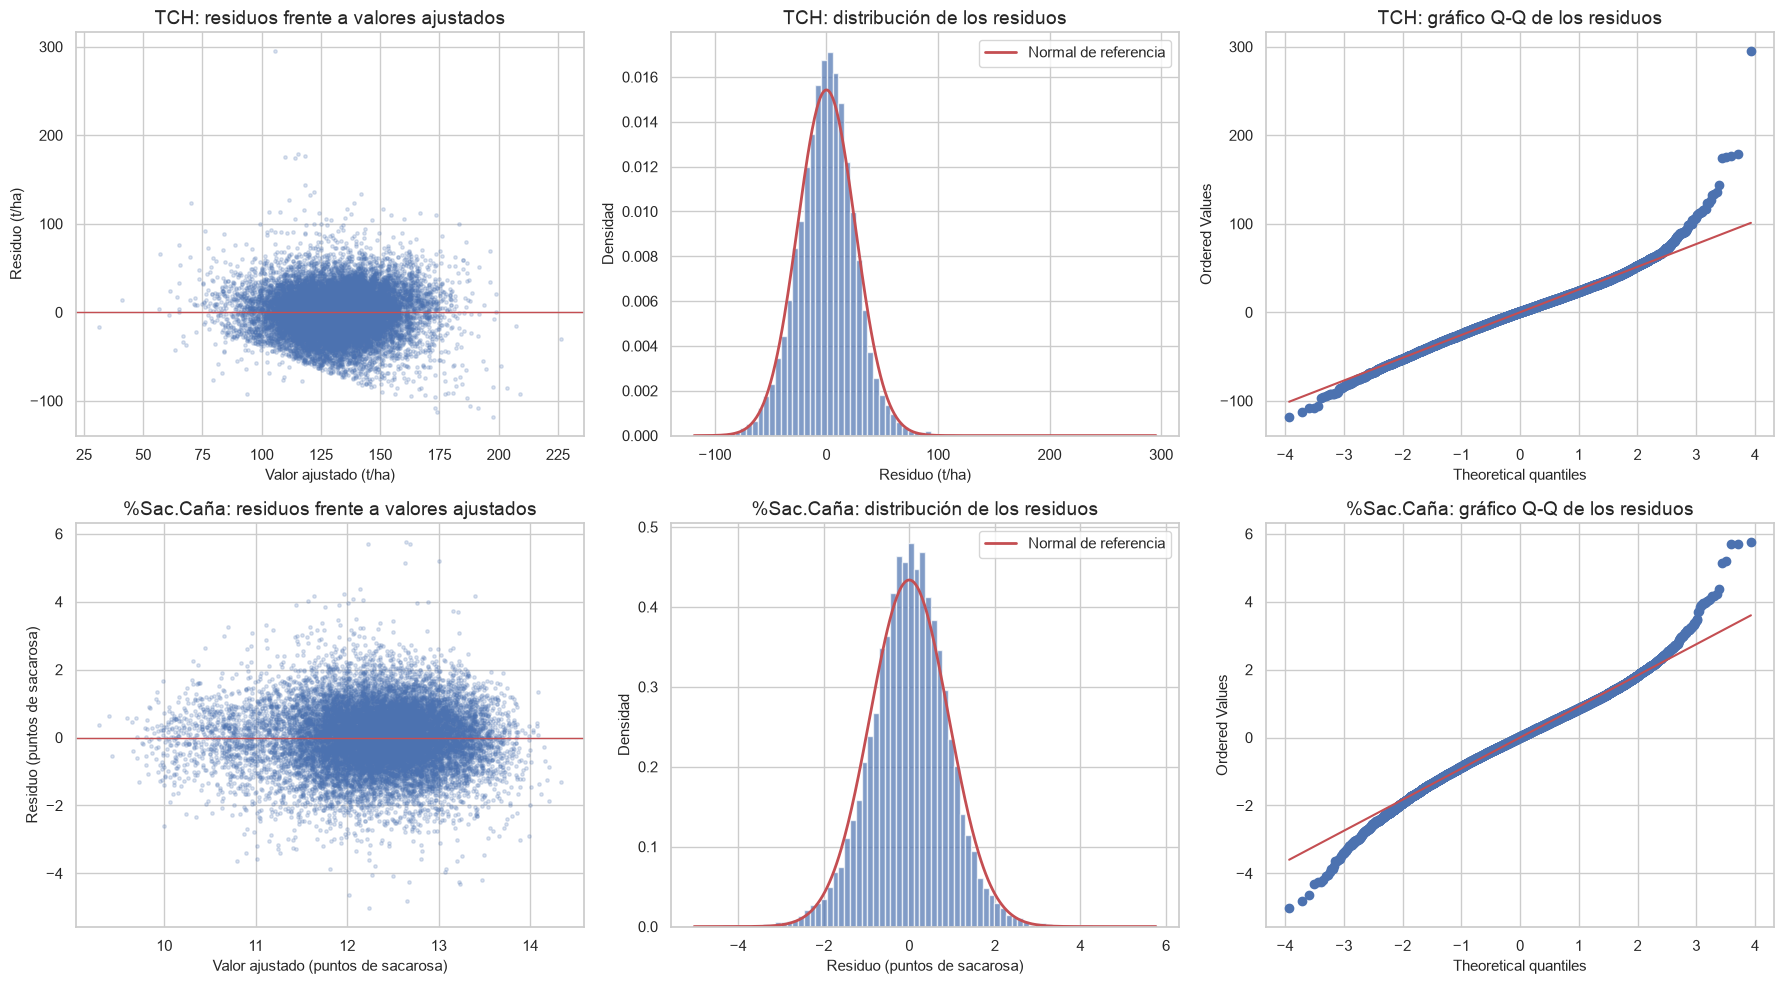

Resumen de las pruebas de supuestos (VIF en la celda de la matriz de diseño):


,TCH,%Sac.Caña
Durbin-Watson (orden por lote),1.346,1.772
Breusch-Pagan LM,702.373,707.324
Breusch-Pagan p-value,2.47e-110,7.32e-112
Shapiro-Wilk W (5000 residuos),0.989,0.984
Shapiro-Wilk p-value,9.15e-20,5.22e-23
Asimetría,0.247,-0.043
Curtosis en exceso,2.424,1.396


In [12]:
# 4.2 Verificación de supuestos: linealidad, independencia, homocedasticidad y normalidad de los residuos
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

UNIDADES = {"TCH": "t/ha", "%Sac.Caña": "puntos de sacarosa"}
ORDEN_POR_LOTE = ["Hacienda", "Suerte", "Período"]
TAMANO_MUESTRA_SHAPIRO = 5000  # límite por encima del cual scipy advierte que el p-value no es exacto


def residuos_ordenados_por_lote(target):
    """Residuos del OLS ordenados por lote y periodo, para que los cortes sucesivos de un lote queden contiguos."""
    datos = datos_por_target[target]
    residuos = pd.Series(ajustes_ols[target]["clasico"].resid.to_numpy(), index=datos.y_train.index)
    orden = df_train.loc[residuos.index, ORDEN_POR_LOTE].sort_values(ORDEN_POR_LOTE).index
    return residuos.loc[orden].to_numpy()


def formatear_supuestos(tabla):
    """p-values en notación científica (algunos son minúsculos) y el resto de estadísticos con 3 decimales."""
    return tabla.apply(
        lambda fila: fila.map(lambda valor: f"{valor:.2e}" if "p-value" in fila.name else f"{valor:.3f}"),
        axis=1,
    )


generador = np.random.default_rng(RANDOM_STATE)
resultados_supuestos = {}
fig, ejes = plt.subplots(2, 3, figsize=(18, 10))
for fila, target in enumerate(TARGETS):
    ajuste = ajustes_ols[target]["clasico"]
    residuos, ajustados = ajuste.resid.to_numpy(), ajuste.fittedvalues.to_numpy()

    # Independencia: Durbin-Watson con los cortes de cada lote en orden cronológico
    estadistico_dw = durbin_watson(residuos_ordenados_por_lote(target))
    # Homocedasticidad: Breusch-Pagan contra los mismos predictores del modelo
    lm_bp, p_bp, _, _ = het_breuschpagan(residuos, ajuste.model.exog)
    # Normalidad: Shapiro-Wilk sobre una muestra aleatoria de residuos
    muestra = generador.choice(residuos, size=min(TAMANO_MUESTRA_SHAPIRO, len(residuos)), replace=False)
    estadistico_sw, p_sw = stats.shapiro(muestra)

    resultados_supuestos[target] = {
        "Durbin-Watson (orden por lote)": estadistico_dw,
        "Breusch-Pagan LM": lm_bp,
        "Breusch-Pagan p-value": p_bp,
        "Shapiro-Wilk W (5000 residuos)": estadistico_sw,
        "Shapiro-Wilk p-value": p_sw,
        "Asimetría": stats.skew(residuos),
        "Curtosis en exceso": stats.kurtosis(residuos),
    }

    # Linealidad y homocedasticidad: los residuos deberían repartirse sin patrón alrededor de 0
    ejes[fila, 0].scatter(ajustados, residuos, s=6, alpha=0.2, color="#4C72B0")
    ejes[fila, 0].axhline(0, color="#C44E52", lw=1)
    ejes[fila, 0].set(title=f"{target}: residuos frente a valores ajustados",
                      xlabel=f"Valor ajustado ({UNIDADES[target]})", ylabel=f"Residuo ({UNIDADES[target]})")

    # Normalidad: histograma frente a una normal con la misma media y desviación estándar
    malla = np.linspace(residuos.min(), residuos.max(), 400)
    ejes[fila, 1].hist(residuos, bins=80, density=True, color="#4C72B0", alpha=0.7)
    ejes[fila, 1].plot(malla, stats.norm.pdf(malla, residuos.mean(), residuos.std()),
                       color="#C44E52", lw=2, label="Normal de referencia")
    ejes[fila, 1].legend()
    ejes[fila, 1].set(title=f"{target}: distribución de los residuos",
                      xlabel=f"Residuo ({UNIDADES[target]})", ylabel="Densidad")

    # Normalidad: los puntos del gráfico Q-Q deberían seguir la diagonal
    stats.probplot(residuos, dist="norm", plot=ejes[fila, 2])
    ejes[fila, 2].set_title(f"{target}: gráfico Q-Q de los residuos")

plt.tight_layout()
plt.show()

print("Resumen de las pruebas de supuestos (VIF en la celda de la matriz de diseño):")
display(formatear_supuestos(pd.DataFrame(resultados_supuestos)))

#### Conclusión de 4.2

**Supuestos.** El modelo lineal cumple el supuesto de colinealidad y, de forma aproximada, el de linealidad. No cumple los de homocedasticidad y normalidad, y el de independencia falla en `TCH`:

| Supuesto | `TCH` | `%Sac.Caña` | Lectura |
|---|---|---|---|
| Linealidad | Residuos sin curvas en el centro de la nube | Residuos sin patrón | Se cumple de forma aproximada. El borde inferior diagonal en `TCH` viene de excluir los lotes de molino con menos de 60 t/ha: en esos lotes, ningún residuo puede quedar por debajo de $60 - \hat{y}$ |
| Independencia | Durbin-Watson = 1.35 | 1.77 | En `TCH` el valor está por debajo de 1.5: hay autocorrelación positiva entre cortes sucesivos del mismo lote, de modo que un lote que supera la predicción en un corte tiende a superarla en el siguiente. En sacarosa el valor está en el rango aceptable |
| Homocedasticidad | Breusch-Pagan: LM = 702.4, p ≈ 1e-110 | LM = 707.3, p ≈ 1e-112 | No se cumple: la varianza del error cambia con los predictores |
| Normalidad | Shapiro-Wilk: W = 0.989, p ≈ 1e-20; curtosis en exceso 2.42 | W = 0.984, p ≈ 1e-23; curtosis en exceso 1.40 | Se rechaza, pero la desviación es moderada. El histograma sigue de cerca a la normal en el centro, y el gráfico Q-Q muestra que la diferencia está en las colas, más pesadas que las de una normal. En `TCH` hay un residuo cercano a +300 t/ha |
| Colinealidad | VIF < 5 en todas las columnas | VIF < 5 en todas las columnas | Se cumple. Si la referencia de una variable fuera una categoría rara, sus demás indicadoras sumarían casi siempre 1 y quedarían casi colineales entre sí; tomar como referencia la categoría más frecuente lo evita |

**Consecuencias para la inferencia.** Con heterocedasticidad y dependencia entre cortes de un mismo lote, los errores estándar clásicos no son válidos. Por eso la significancia de los coeficientes se decide con los errores agrupados por hacienda, que admiten las dos cosas; como cada lote pertenece a una sola hacienda, el agrupamiento también cubre la correlación entre sus cortes. La desviación de la normalidad pesa poco con más de 16 000 registros. Las columnas presentes en menos de 10 haciendas quedaron fuera de la interpretación.

**Lo que dice el modelo.** En tonelaje dominan el ciclo (la edad al corte y el número de corte), la variedad, la zona, la lluvia del inicio del ciclo y una tendencia decreciente entre años. En sacarosa dominan el madurante, la lluvia del final del ciclo y el mes de corte; la edad y el año no influyen. Los dos targets responden a factores distintos, y algunas variedades muestran una disyuntiva entre cantidad y calidad.

**Lo que no alcanza a capturar.** El R² dentro del entrenamiento es de 0.314 en `TCH` y 0.355 en `%Sac.Caña`. El gráfico de residuos frente a valores ajustados no muestra curvas, pero resume todos los predictores en uno solo, así que no puede revelar no linealidades de una variable en particular ni interacciones entre variables. El EDA encontró ambas: el codo del número de corte, que una pendiente única no representa, y el cambio de signo del efecto de la lluvia temprana según la variedad. Además, la autocorrelación en `TCH` indica que cada lote tiene un nivel propio de rendimiento que los predictores no recogen. Estos son los argumentos para probar los modelos basados en árboles de la sección 5.

### 4.3 Regresión regularizada: Ridge y Lasso

Ridge y Lasso estiman la misma regresión lineal, pero agregan a la suma de errores cuadrados una penalización sobre la magnitud de los coeficientes. En la forma que usa scikit-learn:

$$\text{Ridge:}\quad \min_{\beta}\; \lVert y - X\beta \rVert_2^2 + \alpha \lVert \beta \rVert_2^2 \qquad\qquad \text{Lasso:}\quad \min_{\beta}\; \frac{1}{2n}\lVert y - X\beta \rVert_2^2 + \alpha \lVert \beta \rVert_1$$

Con $\alpha = 0$ ambos coinciden con la regresión lineal, y a medida que $\alpha$ crece los coeficientes se encogen hacia 0. Ridge los encoge todos sin anular ninguno. Lasso, por la forma del valor absoluto, lleva algunos exactamente a 0, así que además selecciona variables. Las dos funciones objetivo están escaladas de forma distinta, por lo que un mismo valor de $\alpha$ no significa lo mismo en los dos modelos.

La penalización depende de la escala de cada predictor: sin estandarizar, un coeficiente en m³ de riego y otro en meses de edad se penalizarían de forma desigual. Por eso el pipeline agrega un `StandardScaler` después del preprocesamiento, ajustado también dentro de cada pliegue.

**Búsqueda de $\alpha$.** Se prueban 15 valores en escala logarítmica para cada modelo con `GridSearchCV`, en los mismos pliegues de la sección 3.3, y se elige el de menor RMSE medio de validación. Si el mejor valor queda en un extremo de la grilla, la grilla se tendría que ampliar. El RMSE del valor elegido es algo optimista, porque se elige y se mide con los mismos pliegues; ese sesgo es igual para todos los modelos que se ajustan así en el notebook, y la estimación final la da el conjunto de prueba en la sección 7.

**Qué se espera.** En 4.1 el error de ajuste de la regresión lineal fue casi igual al de validación, es decir, el modelo no sobreajusta. Si es así, la penalización no debería mejorar mucho el error. Lo que se busca con esta sección es confirmarlo, y con Lasso, ver qué columnas se pueden eliminar sin perder desempeño.

In [13]:
# 4.3 Ridge y Lasso: búsqueda de la penalización con GridSearchCV en los pliegues fijos
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV

GRILLAS_REGULARIZADOS = {
    "Ridge": (Ridge(), {"modelo__alpha": np.logspace(-2, 5, 15)}),
    "Lasso": (Lasso(max_iter=20_000), {"modelo__alpha": np.logspace(-4, 1, 15)}),
}

# Búsquedas ajustadas por (modelo, target); se reutilizan en las secciones siguientes
busquedas = {}


def registrar_mejor_configuracion(nombre_modelo, target, busqueda):
    """Registra las métricas por pliegue de la mejor configuración, en el mismo formato que evaluar_cv."""
    resultados, mejor = busqueda.cv_results_, busqueda.best_index_
    por_pliegue = lambda clave: np.array([resultados[f"split{k}_{clave}"][mejor] for k in range(busqueda.n_splits_)])
    registrar_cv(nombre_modelo, target,
                 rmse=-por_pliegue("test_RMSE"), mae=-por_pliegue("test_MAE"), r2=por_pliegue("test_R2"),
                 rmse_ajuste=-por_pliegue("train_RMSE"))


def buscar_hiperparametros(nombre_modelo, pipeline, grilla, target, n_procesos=-1):
    """GridSearchCV en los pliegues fijos del target, con el RMSE como criterio. Reajusta la mejor
    configuración con todo el entrenamiento y registra sus métricas por pliegue.
    n_procesos limita los ajustes en paralelo cuando cada modelo ocupa mucha memoria (-1: todos los núcleos)."""
    datos = datos_por_target[target]
    busqueda = GridSearchCV(
        pipeline, grilla, cv=datos.pliegues, scoring=METRICAS_CV, refit="RMSE",
        return_train_score=True, n_jobs=n_procesos,
    )
    busqueda.fit(datos.X_train, datos.y_train)
    busquedas[(nombre_modelo, target)] = busqueda
    registrar_mejor_configuracion(nombre_modelo, target, busqueda)
    return busqueda


for target in TARGETS:
    for nombre_modelo, (modelo, grilla) in GRILLAS_REGULARIZADOS.items():
        busqueda = buscar_hiperparametros(nombre_modelo, crear_pipeline(modelo, escalar=True), grilla, target)
        valores_alpha = grilla["modelo__alpha"]
        mejor_alpha = busqueda.best_params_["modelo__alpha"]
        en_extremo = mejor_alpha in (valores_alpha.min(), valores_alpha.max())
        print(f"{target} | {nombre_modelo}: mejor alpha = {mejor_alpha:.4g} "
              f"({'en el extremo de la grilla' if en_extremo else 'dentro de la grilla'}) | "
              f"RMSE de validación = {-busqueda.best_score_:.3f}")

print("\nValidación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv(["Regresión lineal", "Ridge", "Lasso"]).round(3))

TCH | Ridge: mejor alpha = 316.2 (dentro de la grilla) | RMSE de validación = 26.606
TCH | Lasso: mejor alpha = 0.07197 (dentro de la grilla) | RMSE de validación = 26.600
%Sac.Caña | Ridge: mejor alpha = 316.2 (dentro de la grilla) | RMSE de validación = 0.929
%Sac.Caña | Lasso: mejor alpha = 0.006105 (dentro de la grilla) | RMSE de validación = 0.929

Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2         \
                              mean    std    mean    std   mean    std   
target    modelo                                                         
TCH       Regresión lineal  26.616  1.288  20.510  1.135  0.267  0.021   
%Sac.Caña Regresión lineal   0.930  0.026   0.716  0.025  0.335  0.055   
TCH       Ridge             26.606  1.294  20.514  1.139  0.268  0.021   
          Lasso             26.600  1.268  20.514  1.117  0.268  0.020   
%Sac.Caña Ridge              0.929  0.026   0.715  0.025  0.335  0.055   
          Lasso              0.929  0.026   0.715  0.025  0.336  0.056   

                           RMSE_ajuste         
                                  mean    std  
target    modelo                               
TCH       Regresión lineal      25.934  0.338  
%Sac.Caña Regresión lineal       0.919  0.007  
TCH       Ridge                 25.937  0.337  
          Lasso                 25.937  0.337  
%Sac.Caña Ridge                  0.919  0.007  
          Lasso                  0.920  0.007

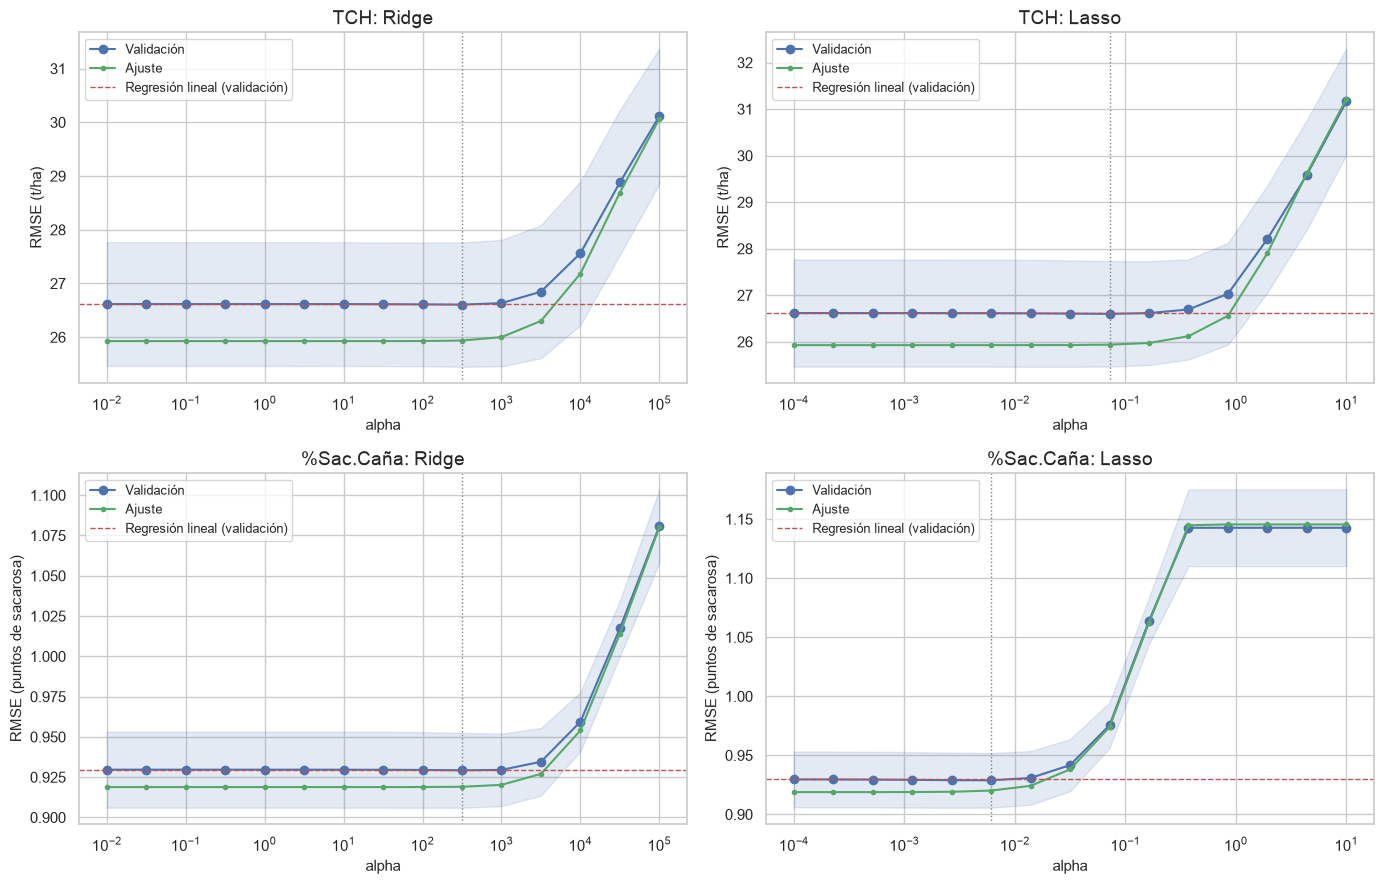

TCH: Lasso conserva 53 de 60 columnas. En cero: ['Luvias 9 -FC', 'Zona_agrup_IP03', 'T.Corte_agrup_NO DEF.', 'Tipo Quema_NO DEF.', 'Mes_03', 'Mes_09', 'Mes_10']
%Sac.Caña: Lasso conserva 50 de 59 columnas. En cero: ['Lluvias seis a nueve', 'Num.Riegos', 'Destino 1=Semilla', 'Zona_agrup_IP03', 'Suelo_agrup_GALPON', 'Suelo_agrup_PALMIRA', 'T.Corte_agrup_NO DEF.', 'Tenencia_agrup_31', 'Tenencia_agrup_OTRAS']


In [14]:
# 4.3 Curvas de validación de alpha y columnas que Lasso lleva a cero
fig, ejes = plt.subplots(len(TARGETS), len(GRILLAS_REGULARIZADOS), figsize=(14, 9))
for fila, target in enumerate(TARGETS):
    rmse_lineal = registro_cv[("Regresión lineal", target)]["RMSE"].mean()
    for columna, nombre_modelo in enumerate(GRILLAS_REGULARIZADOS):
        busqueda = busquedas[(nombre_modelo, target)]
        resultados = busqueda.cv_results_
        valores_alpha = np.array(resultados["param_modelo__alpha"], dtype=float)
        rmse_validacion = -resultados["mean_test_RMSE"]
        desviacion = resultados["std_test_RMSE"]

        eje = ejes[fila, columna]
        eje.plot(valores_alpha, rmse_validacion, marker="o", color="#4C72B0", label="Validación")
        eje.fill_between(valores_alpha, rmse_validacion - desviacion, rmse_validacion + desviacion,
                         color="#4C72B0", alpha=0.15)
        eje.plot(valores_alpha, -resultados["mean_train_RMSE"], marker=".", color="#55A868", label="Ajuste")
        eje.axhline(rmse_lineal, color="#C44E52", ls="--", lw=1, label="Regresión lineal (validación)")
        eje.axvline(busqueda.best_params_["modelo__alpha"], color="gray", ls=":", lw=1)
        eje.set(xscale="log", title=f"{target}: {nombre_modelo}", xlabel="alpha",
                ylabel=f"RMSE ({UNIDADES[target]})")
        eje.legend(fontsize=9)
plt.tight_layout()
plt.show()

# Lasso reajustado con todo el entrenamiento y el alpha elegido: qué columnas quedan en cero
for target in TARGETS:
    mejor_lasso = busquedas[("Lasso", target)].best_estimator_
    nombres_columnas = mejor_lasso.named_steps["preprocesamiento"].get_feature_names_out()
    coeficientes = pd.Series(mejor_lasso.named_steps["modelo"].coef_, index=nombres_columnas)
    en_cero = coeficientes[coeficientes == 0].index.tolist()
    print(f"{target}: Lasso conserva {len(coeficientes) - len(en_cero)} de {len(coeficientes)} columnas. "
          f"En cero: {en_cero or 'ninguna'}")

#### Conclusión de 4.3

La regularización no mejora a la regresión lineal. Con el $\alpha$ elegido, el RMSE de validación baja de 26.616 a 26.606 t/ha con Ridge y a 26.600 con Lasso en `TCH`, y de 0.930 a 0.929 puntos con ambos en `%Sac.Caña`. Son diferencias unas 80 veces menores que la variación entre pliegues (1.29 t/ha y 0.026 puntos), y el MAE y el R² no cambian. En los cuatro casos el mejor $\alpha$ quedó dentro de la grilla.

Las curvas de validación muestran por qué. El error de ajuste y el de validación son planos mientras la penalización es pequeña, y cuando empieza a pesar (desde $\alpha \approx 10^3$ en Ridge y $\alpha \approx 0.1$ en Lasso) suben juntos. No hay un tramo en que la penalización reduzca el error de validación a costa del de ajuste, que sería la señal de un modelo con varianza que controlar; la brecha entre los dos se mantiene en unas 0.7 t/ha y 0.01 puntos. El valor elegido en Ridge ($\alpha = 316$) es además una penalización débil: en la forma de scikit-learn la suma de errores no se divide por el número de registros, y con más de 16 000 registros ese $\alpha$ apenas encoge los coeficientes. Esto confirma lo visto en 4.1: la regresión lineal no sobreajusta, y su error es de sesgo.

Lasso conserva 53 de 60 columnas en `TCH` y 50 de 59 en `%Sac.Caña`, y todas las que lleva a cero eran no significativas con errores agrupados en 4.2 o tenían un solo registro:

- **`TCH`:** la lluvia de 9 meses al corte, la zona IP03, los niveles sin definir de tipo de corte y de quema, y los meses de corte 03, 09 y 10.
- **`%Sac.Caña`:** la lluvia de 6 a 9 meses, el número de riegos, `Destino 1=Semilla`, la zona IP03, los suelos Galpón y Palmira, el tipo de corte sin definir y las tenencias 31 y `OTRAS`.

Las dos lecturas del modelo lineal, la inferencia de `statsmodels` y la selección de Lasso, coinciden en qué predictores no aportan. El caso de los meses es ilustrativo: septiembre y octubre se anulan en `TCH`, pero en `%Sac.Caña` estaban entre los coeficientes más grandes. El mes de corte influye en la calidad de la caña, no en su tonelaje. Que Lasso conserve casi todas las columnas indica, además, que la limitación del modelo lineal no viene de tener predictores de sobra, sino de la forma aditiva y lineal que les impone.

### Conclusión de la sección 4

Los cuatro modelos de referencia, evaluados en los mismos pliegues agrupados por hacienda:

| Modelo | `TCH`: RMSE (t/ha) | `TCH`: MAE | `TCH`: R² | `%Sac.Caña`: RMSE (puntos) | `%Sac.Caña`: MAE | `%Sac.Caña`: R² |
|---|---|---|---|---|---|---|
| Media constante | 31.16 ± 1.28 | 24.50 | −0.005 | 1.143 ± 0.036 | 0.894 | −0.002 |
| Regresión lineal | 26.62 ± 1.29 | 20.51 | 0.267 | 0.930 ± 0.026 | 0.716 | 0.335 |
| Ridge | 26.61 ± 1.29 | 20.51 | 0.268 | 0.929 ± 0.026 | 0.715 | 0.335 |
| Lasso | 26.60 ± 1.27 | 20.51 | 0.268 | 0.929 ± 0.026 | 0.715 | 0.336 |

La regresión lineal explica cerca de un cuarto de la variación del tonelaje y un tercio de la de la sacarosa en fincas que no vio durante el ajuste. La regularización no la mejora, así que la regresión lineal, el más simple de los tres, queda como modelo de referencia: los modelos de la sección 5 tienen que bajar de 26.6 t/ha y 0.93 puntos de RMSE. Como las diferencias entre modelos pueden ser pequeñas frente a la variación entre pliegues, en la sección 6 la comparación se hace pliegue a pliegue.

Además del desempeño, la sección dejó la lectura del modelo que se usará para contrastar la interpretabilidad de los modelos avanzados en la sección 8. Los factores con efecto claro sobre el tonelaje son el ciclo, la variedad, la zona y la lluvia del inicio del ciclo. Sobre la sacarosa, el madurante, la lluvia del final del ciclo y el mes de corte.

## 5. Modelos avanzados

La sección 4 mostró que la regresión lineal no sobreajusta y que su error es de sesgo: la forma aditiva y lineal no alcanza a describir la relación entre los predictores y los targets. Hay razones concretas para esperar que un modelo basado en árboles lo haga mejor:

- **Relaciones no lineales.** El TCH cae con el número de corte hasta el corte 9 o 10 y después se aplana, y la distancia al ingenio se relaciona con el TCH por tramos. Un árbol divide cada predictor en intervalos y asigna a cada uno su propio nivel, así que puede representar un codo o un escalón sin que se especifique su forma.
- **Interacciones.** En el EDA, el efecto de la lluvia temprana sobre el TCH cambia de signo según la variedad. Un modelo lineal solo representa esa interacción si se agrega como término explícito; un árbol la captura cuando divide primero por variedad y después por lluvia.
- **Supuestos.** Los árboles no suponen errores normales ni de varianza constante, dos supuestos que el modelo lineal no cumplió en 4.2, y no necesitan predictores estandarizados.

Los dos modelos combinan muchos árboles de forma distinta. **Random Forest** promedia árboles profundos entrenados en muestras bootstrap y con un subconjunto aleatorio de predictores en cada división: el promedio reduce la varianza de árboles individuales muy flexibles. **XGBoost** construye árboles poco profundos en secuencia, y cada uno corrige el error que dejaron los anteriores: reduce sobre todo el sesgo.

También tienen límites. No extrapolan fuera del rango de valores visto en el ajuste, y sus predicciones no se leen directamente como coeficientes. Su interpretación se aborda en la sección 8.

Los dos se ajustan en los mismos pliegues y con los mismos predictores del modelo lineal, de modo que cualquier diferencia de desempeño se debe al modelo.

### 5.1 Random Forest

**Búsqueda por etapas.** Random Forest y XGBoost tienen varios hiperparámetros, y una grilla con todas sus combinaciones sería inviable: con cinco hiperparámetros de tres a seis valores cada uno, Random Forest ya sumaría más de 800 configuraciones, es decir, más de 8000 bosques entre pliegues y targets. Por eso la búsqueda se hace por etapas. En cada etapa, `GridSearchCV` prueba todas las combinaciones de un grupo de hiperparámetros que interactúan entre sí, con los mejores valores de las etapas anteriores fijos. Cada grilla incluye el valor vigente, así que el error de validación no puede empeorar de una etapa a la siguiente. La búsqueda supone que la interacción entre grupos es menor que dentro de cada grupo. Para verificarlo, la última etapa repite la primera con los valores finales de las demás: si el resultado no cambia, el supuesto se sostiene. Además, con más configuraciones el RMSE de la mejor es algo más optimista, y por eso la estimación final la da el conjunto de prueba.

**Hiperparámetros que se buscan**

| Etapa | Hiperparámetro | Qué controla | Valores |
|---|---|---|---|
| 1. Estructura | `max_features` | Fracción de predictores que se considera en cada división. Una fracción baja hace los árboles más distintos entre sí, lo que mejora el promedio, pero cada árbol es menos preciso | 0.1, 0.15, 0.2, 0.33, 0.5, 1.0 |
| | `min_samples_leaf` | Mínimo de registros por hoja: qué tan detallado es cada árbol. Con 1, cada árbol crece hasta separar casi cada registro de su muestra | 1, 2, 5, 10, 40 |
| 2. Muestreo y profundidad | `max_samples` | Tamaño de la muestra bootstrap de cada árbol, como fracción del entrenamiento. Muestras más pequeñas dan árboles más diversos | 0.5, 0.75, completa |
| | `max_depth` | Profundidad máxima de cada árbol | 12, 20, sin límite |
| 3. Número de árboles | `n_estimators` | Cuántos árboles se promedian. Más árboles no causan sobreajuste, solo estabilizan el promedio; esta etapa comprueba desde cuántos deja de mejorar | 150, 300, 600 |
| 4. Revisión de la estructura | `max_features`, `min_samples_leaf` | Segunda pasada de la etapa 1 con el muestreo, la profundidad y el número de árboles ya elegidos | Los de la etapa 1 |

En total son 72 configuraciones por target. Una primera búsqueda, con `max_features` desde 0.2 y `min_samples_leaf` desde 2, dejó el óptimo de `TCH` en esa esquina de la grilla y con el error todavía bajando, así que la grilla se extendió hacia valores menores. Los valores intermedios que quedaron lejos del óptimo en los dos targets (`max_features` = 0.75 y `min_samples_leaf` = 20) se quitaron para compensar el costo, pero se conservaron los extremos 1.0 y 40, de modo que la grilla sigue cubriendo todo el rango.

Con hojas de un registro y 600 árboles, cada bosque ocupa cientos de MB, así que la búsqueda de Random Forest limita a cuatro los ajustes en paralelo para no exceder la memoria del equipo.

**Hiperparámetros que no se buscan**

| Hiperparámetro | Motivo |
|---|---|
| `min_samples_split` | Es redundante con `min_samples_leaf`: si cada hoja necesita al menos $L$ registros, toda división necesita al menos $2L$, así que cualquier valor de `min_samples_split` menor o igual que $2L$ no tiene efecto |
| `max_leaf_nodes`, `min_impurity_decrease`, `ccp_alpha` | Son otras formas de limitar el tamaño de los árboles, que ya controlan `min_samples_leaf` y `max_depth` |
| `bootstrap` | `max_samples` ya cubre el muestreo; quitar el bootstrap elimina una fuente de diversidad entre árboles |
| `criterion` | El error cuadrático es coherente con el RMSE como criterio de selección. El error absoluto es órdenes de magnitud más lento con más de 16 000 registros, y `friedman_mse` da resultados casi idénticos |

**Resultados guardados.** La búsqueda tarda varios minutos, así que el resultado de cada modelo y target se guarda en la carpeta `resultados/`: el modelo final, la bitácora de etapas, los resultados de todas las configuraciones y la duración. Al ejecutar de nuevo el notebook, si las grillas no cambiaron, la búsqueda se carga en lugar de repetirse. Para recalcularla se cambia `RECALCULAR_BUSQUEDAS` a `True`; hay que hacerlo también si cambian los datos o el preprocesamiento, porque el archivo guardado no lo detecta.

In [15]:
# 5.1 Random Forest: búsqueda de hiperparámetros por etapas en los pliegues fijos
from datetime import datetime
from time import perf_counter

import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid

RECALCULAR_BUSQUEDAS = False  # True repite las búsquedas aunque haya resultados guardados
CARPETA_RESULTADOS = Path("resultados")
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Con hojas de 1 registro y 600 árboles, cada bosque ocupa cientos de MB: se limitan los ajustes en paralelo
PROCESOS_RANDOM_FOREST = 4

GRILLA_ESTRUCTURA_RANDOM_FOREST = {
    "modelo__max_features": [0.1, 0.15, 0.2, 0.33, 0.5, 1.0],  # 1.0 es el máximo posible: todos los predictores
    "modelo__min_samples_leaf": [1, 2, 5, 10, 40],
}
ETAPAS_RANDOM_FOREST = {
    "1. Estructura": GRILLA_ESTRUCTURA_RANDOM_FOREST,
    "2. Muestreo y profundidad": {
        "modelo__max_samples": [0.5, 0.75, None],  # None: muestra bootstrap del tamaño del entrenamiento
        "modelo__max_depth": [12, 20, None],       # None: sin límite de profundidad
    },
    "3. Número de árboles": {
        "modelo__n_estimators": [150, 300, 600],
    },
    # Segunda pasada: verifica que la estructura elegida siga siendo la mejor con las demás etapas ya fijadas
    "4. Revisión de la estructura": GRILLA_ESTRUCTURA_RANDOM_FOREST,
}

# Detalle de cada búsqueda por etapas, por (modelo, target): bitácora, resultados por etapa, configuración y duración
detalle_busquedas = {}


def parametros_en_extremo(busqueda, grilla):
    """Hiperparámetros cuyo mejor valor quedó en el borde de su grilla, que podría ampliarse.
    None (sin límite, muestra completa) cuenta como el extremo superior."""
    en_extremo = []
    for parametro, valores in grilla.items():
        numericos = [valor for valor in valores if isinstance(valor, (int, float))]
        if not numericos:
            continue
        extremo_superior = None if None in valores else max(numericos)
        if busqueda.best_params_[parametro] in (min(numericos), extremo_superior):
            en_extremo.append(parametro.removeprefix("modelo__"))
    return en_extremo


def ruta_resultados(nombre_modelo, target):
    """Archivo de la búsqueda de un modelo y target, con un nombre sin espacios ni símbolos."""
    nombre = f"{nombre_modelo}_{target}".lower().replace(" ", "_").replace("%", "").replace(".", "")
    return CARPETA_RESULTADOS / f"busqueda_{nombre}.joblib"


def cargar_busqueda_guardada(ruta, etapas):
    """Búsqueda guardada, si existe, se puede leer y corresponde a las mismas etapas; si no, None."""
    if RECALCULAR_BUSQUEDAS or not ruta.exists():
        return None
    try:
        guardado = joblib.load(ruta)
    except Exception as error:  # archivo dañado o guardado con otra versión de las librerías
        print(f"  No se pudo leer {ruta} ({type(error).__name__}); la búsqueda se repite.")
        return None
    if not isinstance(guardado, dict) or guardado.get("etapas") != etapas:
        print(f"  {ruta} corresponde a otras grillas; la búsqueda se repite.")
        return None
    return guardado


def guardar_busqueda(ruta, contenido):
    """Guarda en un archivo temporal y lo renombra al terminar, para que una interrupción no deje un archivo
    a medias. Si no se puede escribir, avisa sin perder los resultados, que siguen en memoria."""
    try:
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta_temporal = ruta.with_suffix(".tmp")
        joblib.dump(contenido, ruta_temporal, compress=3)
        ruta_temporal.replace(ruta)
        return True
    except OSError as error:
        print(f"  No se pudo guardar {ruta} ({error}); los resultados quedan solo en memoria.")
        return False


def ejecutar_etapas(nombre_modelo, pipeline, etapas, target, n_procesos):
    """GridSearchCV por etapas: cada etapa busca un grupo de hiperparámetros con los mejores valores de las
    etapas anteriores fijos. Muestra el avance de cada etapa y devuelve la búsqueda de la última, que
    contiene la configuración completa."""
    n_pliegues = datos_por_target[target].pliegues.get_n_splits()
    mejores, bitacora, resultados_etapas = {}, [], {}
    for nombre_etapa, grilla in etapas.items():
        n_configuraciones = len(ParameterGrid(grilla))
        print(f"  [{datetime.now():%H:%M}] {nombre_modelo} | {target} | {nombre_etapa}: {n_configuraciones} "
              f"configuraciones × {n_pliegues} pliegues = {n_configuraciones * n_pliegues} ajustes", flush=True)
        inicio_etapa = perf_counter()

        pipeline.set_params(**mejores)  # fija lo elegido en las etapas anteriores
        busqueda = buscar_hiperparametros(nombre_modelo, pipeline, grilla, target, n_procesos=n_procesos)
        mejores.update(busqueda.best_params_)
        minutos_etapa = (perf_counter() - inicio_etapa) / 60
        print(f"    terminada en {minutos_etapa:.1f} min | RMSE de validación = {-busqueda.best_score_:.3f}",
              flush=True)

        resultados_etapas[nombre_etapa] = pd.DataFrame(busqueda.cv_results_)
        bitacora.append({
            "etapa": nombre_etapa,
            "valores elegidos": ", ".join(f"{parametro.removeprefix('modelo__')} = {valor}"
                                          for parametro, valor in busqueda.best_params_.items()),
            "RMSE validación": -busqueda.best_score_,
            "en el extremo": ", ".join(parametros_en_extremo(busqueda, grilla)) or "-",
            "minutos": minutos_etapa,
        })
    configuracion = {parametro.removeprefix("modelo__"): valor for parametro, valor in mejores.items()}
    detalle = {"bitacora": pd.DataFrame(bitacora).set_index("etapa"),
               "resultados_etapas": resultados_etapas, "configuracion": configuracion}
    return busqueda, detalle


def buscar_por_etapas(nombre_modelo, pipeline, etapas, target, n_procesos=-1):
    """Búsqueda por etapas con resultados guardados: si hay un archivo válido con las mismas etapas, se carga
    y se registra; si no, se ejecuta la búsqueda y se guarda."""
    ruta = ruta_resultados(nombre_modelo, target)
    guardado = cargar_busqueda_guardada(ruta, etapas)

    if guardado is not None:
        busqueda, detalle, origen = guardado["busqueda"], guardado["detalle"], f"cargada de {ruta}"
        busquedas[(nombre_modelo, target)] = busqueda
        registrar_mejor_configuracion(nombre_modelo, target, busqueda)
    else:
        inicio = perf_counter()
        busqueda, detalle = ejecutar_etapas(nombre_modelo, pipeline, etapas, target, n_procesos)
        detalle["minutos"] = (perf_counter() - inicio) / 60
        guardada = guardar_busqueda(ruta, {"etapas": etapas, "busqueda": busqueda, "detalle": detalle})
        origen = f"calculada y guardada en {ruta}" if guardada else "calculada (sin guardar)"

    detalle_busquedas[(nombre_modelo, target)] = detalle
    return busqueda, detalle, origen


for target in TARGETS:
    bosque = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)
    busqueda, detalle, origen = buscar_por_etapas("Random Forest", crear_pipeline(bosque), ETAPAS_RANDOM_FOREST,
                                                  target, n_procesos=PROCESOS_RANDOM_FOREST)
    print(f"\n{target}: búsqueda {origen} ({detalle['minutos']:.1f} min en total)")
    print(f"  Configuración final: {detalle['configuracion']}")
    display(detalle["bitacora"].round(3))

print("\nValidación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv(["Regresión lineal", "Random Forest"]).round(3))

  resultados/busqueda_random_forest_tch.joblib corresponde a otras grillas; la búsqueda se repite.
  [15:59] Random Forest | TCH | 1. Estructura: 30 configuraciones × 5 pliegues = 150 ajustes
    terminada en 4.4 min | RMSE de validación = 25.469
  [16:03] Random Forest | TCH | 2. Muestreo y profundidad: 9 configuraciones × 5 pliegues = 45 ajustes
    terminada en 0.8 min | RMSE de validación = 25.469
  [16:04] Random Forest | TCH | 3. Número de árboles: 3 configuraciones × 5 pliegues = 15 ajustes
    terminada en 0.6 min | RMSE de validación = 25.464
  [16:05] Random Forest | TCH | 4. Revisión de la estructura: 30 configuraciones × 5 pliegues = 150 ajustes


/Users/juan/Documents/Maestria/PrimerSemestre/AprendizajeAutomaticoII/TallerFinal/env/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


    terminada en 8.7 min | RMSE de validación = 25.464

TCH: búsqueda calculada y guardada en resultados/busqueda_random_forest_tch.joblib (14.4 min en total)
  Configuración final: {'max_features': 0.2, 'min_samples_leaf': 2, 'max_depth': None, 'max_samples': None, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_features = 0.2, min_samples_leaf = 2",25.469,-,4.398
2. Muestreo y profundidad,"max_depth = None, max_samples = None",25.469,"max_samples, max_depth",0.761
3. Número de árboles,n_estimators = 600,25.464,n_estimators,0.585
4. Revisión de la estructura,"max_features = 0.2, min_samples_leaf = 2",25.464,-,8.701


  resultados/busqueda_random_forest_saccaña.joblib corresponde a otras grillas; la búsqueda se repite.
  [16:14] Random Forest | %Sac.Caña | 1. Estructura: 30 configuraciones × 5 pliegues = 150 ajustes
    terminada en 4.3 min | RMSE de validación = 0.866
  [16:18] Random Forest | %Sac.Caña | 2. Muestreo y profundidad: 9 configuraciones × 5 pliegues = 45 ajustes
    terminada en 1.1 min | RMSE de validación = 0.866
  [16:19] Random Forest | %Sac.Caña | 3. Número de árboles: 3 configuraciones × 5 pliegues = 15 ajustes
    terminada en 0.7 min | RMSE de validación = 0.865
  [16:20] Random Forest | %Sac.Caña | 4. Revisión de la estructura: 30 configuraciones × 5 pliegues = 150 ajustes
    terminada en 7.1 min | RMSE de validación = 0.865

%Sac.Caña: búsqueda calculada y guardada en resultados/busqueda_random_forest_saccaña.joblib (13.1 min en total)
  Configuración final: {'max_features': 0.33, 'min_samples_leaf': 2, 'max_depth': None, 'max_samples': 0.75, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_features = 0.33, min_samples_leaf = 2",0.866,-,4.262
2. Muestreo y profundidad,"max_depth = None, max_samples = 0.75",0.866,max_depth,1.061
3. Número de árboles,n_estimators = 600,0.865,n_estimators,0.700
4. Revisión de la estructura,"max_features = 0.33, min_samples_leaf = 2",0.865,-,7.096



Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2         \
                              mean    std    mean    std   mean    std   
target    modelo                                                         
TCH       Regresión lineal  26.616  1.288  20.510  1.135  0.267  0.021   
%Sac.Caña Regresión lineal   0.930  0.026   0.716  0.025  0.335  0.055   
TCH       Random Forest     25.464  1.532  19.482  1.441  0.329  0.030   
%Sac.Caña Random Forest      0.865  0.029   0.658  0.028  0.424  0.051   

                           RMSE_ajuste         
                                  mean    std  
target    modelo                               
TCH       Regresión lineal      25.934  0.338  
%Sac.Caña Regresión lineal       0.919  0.007  
TCH       Random Forest         13.249  0.174  
%Sac.Caña Random Forest          0.494  0.004

TCH | RMSE de validación por número de árboles → 150 árboles: 25.513, 300 árboles: 25.469, 600 árboles: 25.464
%Sac.Caña | RMSE de validación por número de árboles → 150 árboles: 0.866, 300 árboles: 0.866, 600 árboles: 0.865


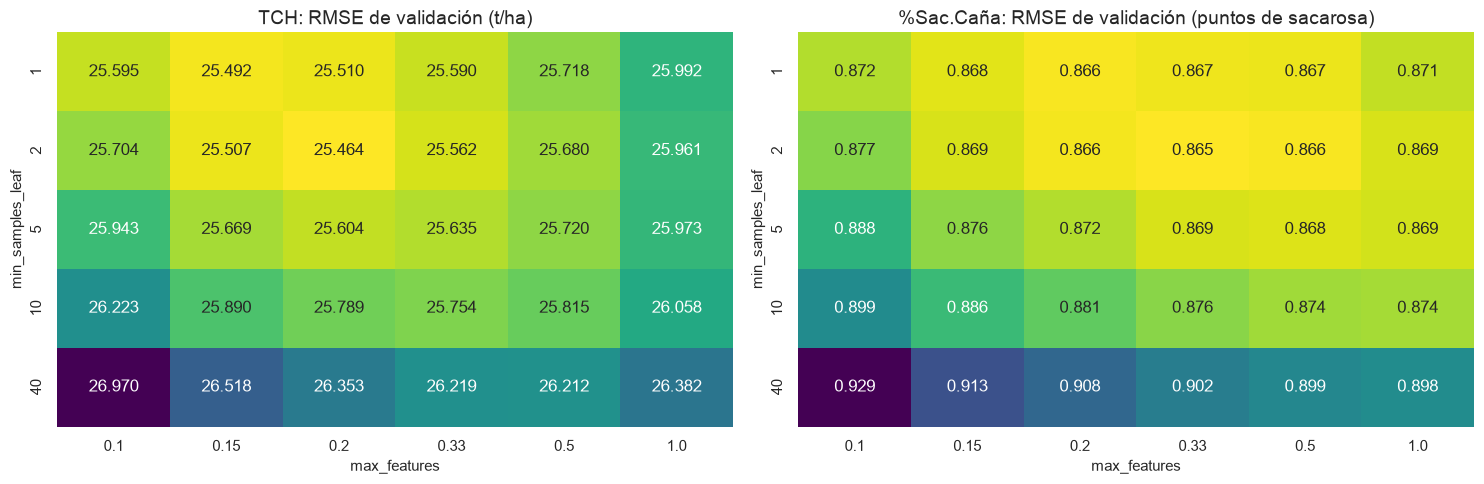

In [16]:
# 5.1 Revisión de los bordes de la grilla: RMSE de validación de la segunda pasada de la estructura
fig, ejes = plt.subplots(1, len(TARGETS), figsize=(15, 5))
for eje, target in zip(ejes, TARGETS):
    detalle = detalle_busquedas[("Random Forest", target)]
    resultados = detalle["resultados_etapas"]["4. Revisión de la estructura"]
    rmse_por_estructura = resultados.assign(RMSE=-resultados["mean_test_RMSE"]).pivot_table(
        index="param_modelo__min_samples_leaf", columns="param_modelo__max_features", values="RMSE",
    )
    sns.heatmap(rmse_por_estructura, annot=True, fmt=".3f", cmap="viridis_r", cbar=False, ax=eje)
    eje.set(title=f"{target}: RMSE de validación ({UNIDADES[target]})",
            xlabel="max_features", ylabel="min_samples_leaf")

    # Efecto del número de árboles, con la estructura de la etapa 1
    arboles = detalle["resultados_etapas"]["3. Número de árboles"]
    efecto_arboles = ", ".join(f"{int(n)} árboles: {-rmse:.3f}"
                               for n, rmse in zip(arboles["param_modelo__n_estimators"], arboles["mean_test_RMSE"]))
    print(f"{target} | RMSE de validación por número de árboles → {efecto_arboles}")
plt.tight_layout()
plt.show()

#### Conclusión de 5.1

**Configuración elegida**

| Hiperparámetro | `TCH` | `%Sac.Caña` |
|---|---|---|
| `max_features` | 0.2 | 0.33 |
| `min_samples_leaf` | 2 | 2 |
| `max_samples` | Muestra completa | 0.75 |
| `max_depth` | Sin límite | Sin límite |
| `n_estimators` | 600 | 600 |

Los dos targets prefieren árboles profundos y muy detallados, con hojas de dos registros, que en cada división consideran solo una fracción de los predictores: unas 12 de las 60 columnas en `TCH` y unas 20 en `%Sac.Caña`. Es la combinación que Random Forest aprovecha mejor, porque cada árbol tiene poco sesgo y el promedio de árboles distintos entre sí reduce su varianza.

**La grilla ya no limita el resultado.** En la segunda pasada de la estructura, el mapa de calor muestra el óptimo en el interior de la grilla ampliada. En `TCH`, bajar `max_features` de 0.2 a 0.15 o a 0.1 sube el RMSE (25.507 y 25.704 t/ha frente a 25.464), y lo mismo ocurre con hojas de un registro (25.510). En `%Sac.Caña` la superficie es casi plana alrededor del óptimo: todas las combinaciones entre 0.2 y 0.5 con hojas de 1 o 2 registros quedan entre 0.865 y 0.867 puntos. Los extremos que la bitácora todavía marca son límites naturales (sin límite de profundidad, muestra completa) o no tienen efecto práctico: pasar de 300 a 600 árboles baja el RMSE apenas 0.005 t/ha y 0.001 puntos, así que el promedio ya está estable. La segunda pasada eligió la misma estructura que la primera en los dos targets, lo que respalda el supuesto de la búsqueda por etapas.

**Desempeño frente a la regresión lineal**

| Target | Métrica | Regresión lineal | Random Forest |
|---|---|---|---|
| `TCH` | RMSE (t/ha) | 26.62 ± 1.29 | 25.46 ± 1.53 |
| | MAE (t/ha) | 20.51 | 19.48 |
| | R² | 0.267 | 0.329 |
| `%Sac.Caña` | RMSE (puntos) | 0.930 ± 0.026 | 0.865 ± 0.029 |
| | MAE (puntos) | 0.716 | 0.658 |
| | R² | 0.335 | 0.424 |

Random Forest reduce el RMSE de validación en 1.15 t/ha (4.3 %) en `TCH` y en 0.065 puntos (7.0 %) en `%Sac.Caña`, y mejora el MAE y el R² en los dos. La ganancia relativa es mayor en sacarosa, lo que sugiere que su relación con los predictores tiene más estructura no lineal o más interacciones que la del tonelaje. Qué variables la explican se revisa en la sección 8, y si la mejora se sostiene en cada pliegue, en la sección 6.

**Error de ajuste frente a validación.** El RMSE en la parte de ajuste (13.25 t/ha y 0.494 puntos) es mucho menor que el de validación. En Random Forest esa brecha es esperable: con hojas de dos registros, cada árbol casi reproduce su muestra. No indica un sobreajuste que haya que corregir, porque el mapa de calor muestra que los árboles más restringidos (hojas de 10 o 40 registros) tienen un error de validación mayor, no menor. El desempeño que importa es el de validación, en fincas que el modelo no vio.

**Costo.** Cada búsqueda tardó entre 13 y 15 minutos con cuatro procesos en paralelo, sobre todo por las dos etapas de estructura con 600 árboles en la segunda.

### 5.2 XGBoost

XGBoost construye los árboles en secuencia. Cada árbol nuevo $f_t$ se ajusta a lo que los anteriores no explicaron, y la predicción se actualiza con un paso pequeño:

$$\hat{y}^{(t)} = \hat{y}^{(t-1)} + \eta\, f_t(x)$$

donde $\eta$ es la tasa de aprendizaje (`learning_rate`). Cada árbol se elige minimizando la pérdida más una penalización sobre su complejidad:

$$\mathcal{L} = \sum_{i} \left(y_i - \hat{y}_i\right)^2 + \sum_{t} \Omega(f_t), \qquad \Omega(f) = \gamma\, T + \tfrac{1}{2}\lambda \lVert w \rVert_2^2 + \alpha \lVert w \rVert_1$$

donde $T$ es el número de hojas del árbol y $w$ los valores que predicen sus hojas. Casi todos los hiperparámetros controlan algún término de estas dos expresiones.

**Hiperparámetros que se buscan.** Se usa la misma búsqueda por etapas de Random Forest. El orden sigue la práctica habitual: primero la forma de los árboles, después la poda, el muestreo y la regularización, y al final la tasa de aprendizaje junto con el número de árboles, que son los dos hiperparámetros que más interactúan.

| Etapa | Hiperparámetro | Qué controla | Valores |
|---|---|---|---|
| 1. Estructura | `max_depth` | Profundidad de cada árbol: de qué orden son las interacciones que puede capturar | 3, 4, 6, 8, 10 |
| | `min_child_weight` | Peso mínimo de una hoja; en regresión con error cuadrático, el número mínimo de registros | 1, 5, 10, 20 |
| 2. Poda | `gamma` ($\gamma$) | Mejora mínima de la pérdida para aceptar una división. Está en las unidades de la pérdida, que son muy distintas en `TCH` (t/ha al cuadrado) y en `%Sac.Caña`, por eso la grilla cubre varios órdenes de magnitud | 0, 0.01, 0.1, 1, 10, 100 |
| 3. Muestreo | `subsample` | Fracción de registros con que se ajusta cada árbol | 0.6, 0.8, 1.0 |
| | `colsample_bytree` | Fracción de predictores disponible para cada árbol | 0.5, 0.7, 0.85, 1.0 |
| 4. Regularización | `reg_alpha` ($\alpha$), `reg_lambda` ($\lambda$) | Penalización L1 y L2 sobre los valores de las hojas | $\alpha$: 0, 0.1, 1, 10; $\lambda$: 0.1, 1, 10, 100 |
| 5. Aprendizaje | `learning_rate` ($\eta$), `n_estimators` | Tamaño del paso y número de árboles. Un paso más pequeño necesita más árboles, pero suele generalizar mejor | $\eta$: 0.01, 0.03, 0.05, 0.1; árboles: 300, 600, 1000, 2000 |
| 6. Revisión de la estructura | `max_depth`, `min_child_weight` | Segunda pasada de la etapa 1 con todo lo demás ya elegido | Los de la etapa 1 |

En total son 90 configuraciones por target. Los valores iniciales son los de la librería, con 300 árboles, y todos están en la grilla de su etapa.

**Hiperparámetros que no se buscan**

| Hiperparámetro | Motivo |
|---|---|
| `colsample_bylevel`, `colsample_bynode` | Muestrean predictores por nivel o por división; cumplen el mismo papel que `colsample_bytree` |
| `max_leaves`, `grow_policy` | Son otra forma de limitar el tamaño de los árboles, que ya controlan `max_depth` y `min_child_weight` |
| `max_bin` | Número de intervalos en que el método `hist` divide cada predictor. El valor por defecto (256) es más fino que la resolución de casi todos los predictores |
| `max_delta_step`, `scale_pos_weight` | Están pensados para clasificación con clases desbalanceadas |
| `booster` | `dart` y `gblinear` son otros algoritmos; el segundo es un modelo lineal |

**Sin parada temprana.** XGBoost puede detener el entrenamiento cuando el error deja de bajar en un conjunto de validación. Aquí no se usa, porque ese conjunto sería el mismo pliegue con el que se mide el desempeño, y el RMSE de validación quedaría sesgado a favor de XGBoost. El número de árboles se elige como un hiperparámetro más, igual que en Random Forest.

**Implementación.** Se usa `XGBRegressor`, la interfaz de XGBoost para scikit-learn, dentro del mismo `Pipeline` que los demás modelos, de modo que el preprocesamiento se reajusta en cada pliegue. Internamente, con `tree_method="hist"`, `XGBRegressor` convierte los datos en un `QuantileDMatrix`, la estructura de datos de XGBoost que agrupa cada predictor en intervalos y ahorra memoria. Usar `DMatrix` directamente obligaría a preprocesar fuera del `Pipeline` y a evaluar XGBoost con un procedimiento distinto al de los demás modelos.

In [17]:
# 5.2 XGBoost: búsqueda de hiperparámetros por etapas en los pliegues fijos
from xgboost import XGBRegressor

GRILLA_ESTRUCTURA_XGBOOST = {
    "modelo__max_depth": [3, 4, 6, 8, 10],
    "modelo__min_child_weight": [1, 5, 10, 20],
}
ETAPAS_XGBOOST = {
    "1. Estructura": GRILLA_ESTRUCTURA_XGBOOST,
    "2. Poda": {
        "modelo__gamma": [0, 0.01, 0.1, 1, 10, 100],  # varios órdenes de magnitud: la escala depende del target
    },
    "3. Muestreo": {
        "modelo__subsample": [0.6, 0.8, 1.0],
        "modelo__colsample_bytree": [0.5, 0.7, 0.85, 1.0],
    },
    "4. Regularización": {
        "modelo__reg_alpha": [0, 0.1, 1, 10],
        "modelo__reg_lambda": [0.1, 1, 10, 100],
    },
    "5. Aprendizaje": {
        "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "modelo__n_estimators": [300, 600, 1000, 2000],
    },
    # Segunda pasada: verifica la estructura con la tasa de aprendizaje y el número de árboles ya elegidos
    "6. Revisión de la estructura": GRILLA_ESTRUCTURA_XGBOOST,
}


def crear_xgboost():
    """XGBoost con los valores iniciales de la búsqueda; cada uno aparece en la grilla de su etapa."""
    return XGBRegressor(
        n_estimators=300, learning_rate=0.1, max_depth=6, min_child_weight=1, gamma=0,
        subsample=1.0, colsample_bytree=1.0, reg_alpha=0, reg_lambda=1,
        tree_method="hist",  # divide cada predictor en intervalos; internamente usa un QuantileDMatrix
        n_jobs=1,            # el paralelismo lo maneja GridSearchCV, con un ajuste por núcleo
        random_state=RANDOM_STATE,
    )


for target in TARGETS:
    busqueda, detalle, origen = buscar_por_etapas("XGBoost", crear_pipeline(crear_xgboost()), ETAPAS_XGBOOST, target)
    print(f"\n{target}: búsqueda {origen} ({detalle['minutos']:.1f} min en total)")
    print(f"  Configuración final: {detalle['configuracion']}")
    display(detalle["bitacora"].round(3))

print("\nValidación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):")
display(resumen_cv(["Regresión lineal", "Random Forest", "XGBoost"]).round(3))


TCH: búsqueda cargada de resultados/busqueda_xgboost_tch.joblib (2.0 min en total)
  Configuración final: {'max_depth': 6, 'min_child_weight': 5, 'gamma': 0, 'colsample_bytree': 1.0, 'subsample': 0.8, 'reg_alpha': 1, 'reg_lambda': 100, 'learning_rate': 0.03, 'n_estimators': 1000}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_depth = 4, min_child_weight = 10",25.449,-,0.355
2. Poda,gamma = 0,25.449,gamma,0.061
3. Muestreo,"colsample_bytree = 1.0, subsample = 0.8",25.413,colsample_bytree,0.111
4. Regularización,"reg_alpha = 1, reg_lambda = 100",25.348,reg_lambda,0.132
5. Aprendizaje,"learning_rate = 0.03, n_estimators = 1000",25.312,-,0.310
6. Revisión de la estructura,"max_depth = 6, min_child_weight = 5",25.239,-,1.000



%Sac.Caña: búsqueda cargada de resultados/busqueda_xgboost_saccaña.joblib (1.6 min en total)
  Configuración final: {'max_depth': 4, 'min_child_weight': 20, 'gamma': 0, 'colsample_bytree': 0.85, 'subsample': 0.8, 'reg_alpha': 0, 'reg_lambda': 10, 'learning_rate': 0.05, 'n_estimators': 600}


,valores elegidos,RMSE validación,en el extremo,minutos
etapa,,,,
1. Estructura,"max_depth = 4, min_child_weight = 20",0.849,min_child_weight,0.342
2. Poda,gamma = 0,0.849,gamma,0.045
3. Muestreo,"colsample_bytree = 0.85, subsample = 0.8",0.848,-,0.098
4. Regularización,"reg_alpha = 0, reg_lambda = 10",0.848,reg_alpha,0.131
5. Aprendizaje,"learning_rate = 0.05, n_estimators = 600",0.845,-,0.306
6. Revisión de la estructura,"max_depth = 4, min_child_weight = 20",0.845,min_child_weight,0.634



Validación cruzada agrupada por hacienda (media y desviación estándar entre los 5 pliegues):


RMSE            MAE            R2         \
                              mean    std    mean    std   mean    std   
target    modelo                                                         
TCH       Regresión lineal  26.616  1.288  20.510  1.135  0.267  0.021   
%Sac.Caña Regresión lineal   0.930  0.026   0.716  0.025  0.335  0.055   
TCH       Random Forest     25.464  1.532  19.482  1.441  0.329  0.030   
%Sac.Caña Random Forest      0.865  0.029   0.658  0.028  0.424  0.051   
TCH       XGBoost           25.239  1.112  19.285  1.021  0.341  0.009   
%Sac.Caña XGBoost            0.845  0.027   0.643  0.024  0.450  0.047   

                           RMSE_ajuste         
                                  mean    std  
target    modelo                               
TCH       Regresión lineal      25.934  0.338  
%Sac.Caña Regresión lineal       0.919  0.007  
TCH       Random Forest         13.249  0.174  
%Sac.Caña Random Forest          0.494  0.004  
TCH       XGBoost               18.061  0.187  
%Sac.Caña XGBoost                0.719  0.008

#### Revisión de los bordes de la grilla

La bitácora de cada target marca algunos hiperparámetros en el extremo de su grilla. Varios de ellos son límites naturales que no se pueden extender: `gamma` = 0 (ninguna poda adicional), `reg_alpha` = 0 (sin penalización L1) y `colsample_bytree` = 1.0 (todos los predictores disponibles para cada árbol). Hay dos que sí podrían estar limitando el resultado:

- En `TCH`, `reg_lambda` = 100, el valor más alto de su grilla.
- En `%Sac.Caña`, `min_child_weight` = 20, también el más alto, elegido tanto en la etapa 1 como en la segunda pasada.

Para decidir si conviene ampliar la grilla, se revisa cómo cambia el RMSE de validación alrededor de esos valores en las tres etapas que combinan dos hiperparámetros: la regularización, la tasa de aprendizaje con el número de árboles, y la segunda pasada de la estructura.

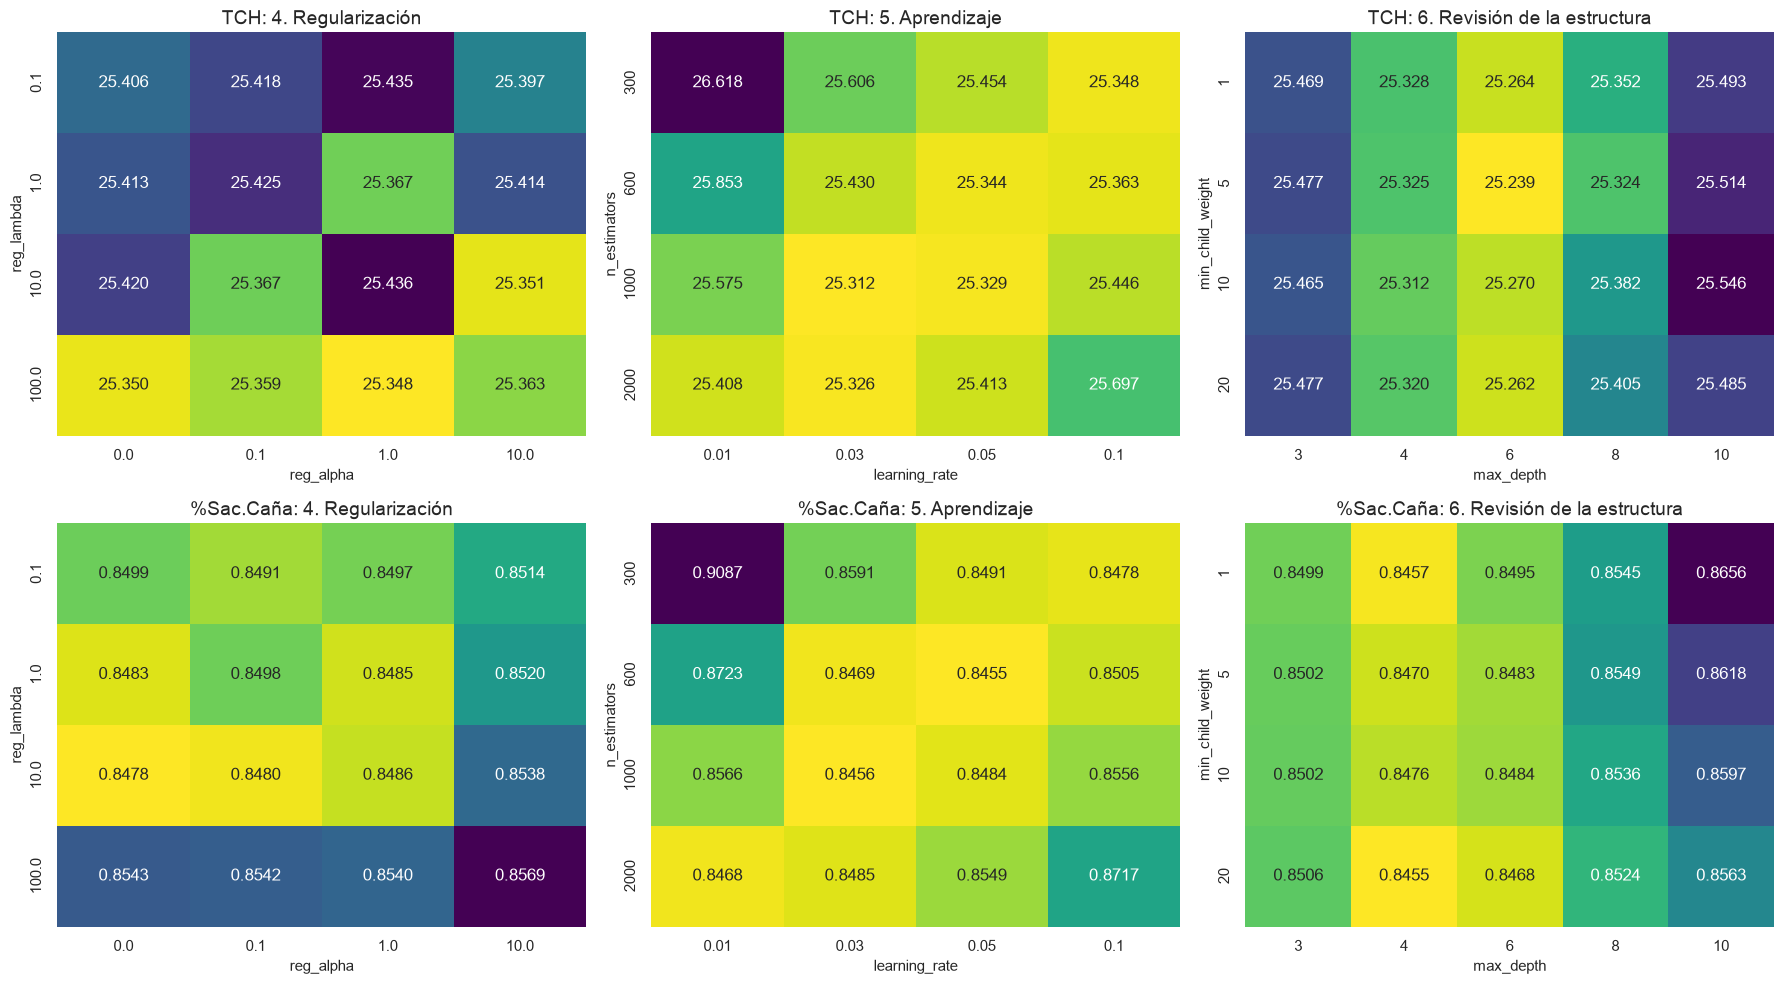

In [18]:
# 5.2 Revisión de los bordes de la grilla de XGBoost: RMSE de validación en las etapas con dos hiperparámetros
ETAPAS_XGBOOST_A_REVISAR = {  # etapa: (hiperparámetro en las filas, hiperparámetro en las columnas)
    "4. Regularización": ("modelo__reg_lambda", "modelo__reg_alpha"),
    "5. Aprendizaje": ("modelo__n_estimators", "modelo__learning_rate"),
    "6. Revisión de la estructura": ("modelo__min_child_weight", "modelo__max_depth"),
}
DECIMALES_MAPA = {"TCH": ".3f", "%Sac.Caña": ".4f"}  # las diferencias en sacarosa están en milésimas

fig, ejes = plt.subplots(len(TARGETS), len(ETAPAS_XGBOOST_A_REVISAR), figsize=(18, 10))
for fila, target in enumerate(TARGETS):
    resultados_etapas = detalle_busquedas[("XGBoost", target)]["resultados_etapas"]
    for columna, (etapa, (parametro_filas, parametro_columnas)) in enumerate(ETAPAS_XGBOOST_A_REVISAR.items()):
        resultados = resultados_etapas[etapa]
        rmse_por_combinacion = resultados.assign(RMSE=-resultados["mean_test_RMSE"]).pivot_table(
            index=f"param_{parametro_filas}", columns=f"param_{parametro_columnas}", values="RMSE",
        )
        eje = ejes[fila, columna]
        sns.heatmap(rmse_por_combinacion, annot=True, fmt=DECIMALES_MAPA[target], cmap="viridis_r", cbar=False, ax=eje)
        eje.set(title=f"{target}: {etapa}", xlabel=parametro_columnas.removeprefix("modelo__"),
                ylabel=parametro_filas.removeprefix("modelo__"))
plt.tight_layout()
plt.show()

#### Conclusión de 5.2

*(Pendiente: se escribe con los resultados de la búsqueda.)*